In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator, NullFormatter

import scipy
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.special import erf

import h5py

import importlib
import delayscan
import delayscan.TRclasses as tr
import delayscan.retrieve

importlib.reload(delayscan.TRclasses)
importlib.reload(delayscan.retrieve)
importlib.reload(delayscan)

from delayscan.retrieve import (
    multiple_gaussians,
    JetFitFunc,
    rebinData,
)

In [2]:
# Load default mpl style
plt.style.use("assets/TRPES.mplstyle")

#Other standard figure widths
fwid = 6.26894
ACSwid = 3.33
thesisWid = 14/2.54

#Extra colours
violet = '#5D3FD3'
red = '#D62828'

blue ='#3A86FF'
green='#6A994E'

## Load and process data

### Calibration data

In [4]:
# Instrument function parameters
# N0 * exp((-x)/l) + 1
IFparams = np.array([-6.90359945,  0.02964122])

# Low eKE cutoff at eKE = 0.126
IFcutoff = 0.126

In [5]:
# TOF to eKE calibration
# Flight tube length (m), time offset (ns), energy offset (eV)
calParams = np.array([  0.62209127, 48.29925437,  1.10221363])

### Data info

In [6]:
#Streaming potentials
SP_250618c = np.array([0.037811958986494684,  0.12997911802896056 ])
SP_250618d = np.array([-0.004002254614469857,  0.20421880748289375 ])



In [7]:
resultsPath = r"data/raw/"

# Data is organised like this (as we do at UCL)
# rf"{date}/{date}{fileIndex}/{date}{fileIndex}/"


In [8]:
# Here we provide the info to upload and process the data
# In each fileInfo_{date}{index} are the scans from each run
# (i.e., between pumping down and venting)
# I have only used one run but potentially could use more

# resultsFolder,date, fn, pump wl, pulseEnergy pump,probe wl, pulseEnergy probe, integration time, approx time 0, SP before, SP after 
fileInfo_250618b = [
    (resultsPath,"180625","dt", 350.0, 5, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","dv", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","dx", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","dz", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","eb", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","ec", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","eg", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","ei", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","ek", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","em", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
]


fileInfos = [fileInfo_250618b,]

In [9]:
allDelays = []
print("Loading files")
for fileInfo in fileInfos:
    scanSet = tr.DelayScanSet()
    for info in fileInfo:

        scan = tr.DelayScan(resultsFolder = info[0],
                            date = info[1],
                            fileIndex = info[2],
                            pumpWavelength = info[3],
                            pumpPulseEnergy = info[4],
                            probeWavelength = info[5],
                            probePulseEnergy = info[6],
                            integrationTime = info[7],
                            timeZero = info[8],
                            SPbefore = info[9],
                            SPafter = info[10],
                            calParams = calParams,
                            IFparams = IFparams,
                            IFcutoff = IFcutoff,
                            )
        scan.importData()
        scan.applyJacobian()
        scan.convert_to_eKE()
        scan.applyInstrumentFunction()
        scan.correctStreamingPotential()
        scan.normaliseByIntegrationTime()
        print(f"- {info[1]}{info[2]}")

        scanSet.append(scan)
    allDelays.append(scanSet)
print("Files loaded")

Loading files
- 180625dt
- 180625dv
- 180625dx
- 180625eb
- 180625ec
- 180625eg
- 180625ei
- 180625ek
- 180625em
Files loaded


### Plot one delay (to determine indices of pp, pump, probe, nothing)

In [10]:
# Select one scan
# (doesn't matter which if they have all been recorded at the same time)

scan = scanSet[0]
#Get total counts
counts = [np.sum(scan.spectra[i::4,1]) for i in range(4)]

#Sort by number of counts
print(np.argsort(counts))

[2 0 3 1]


0: 71.7043 mm, tot counts: 1770
1: 71.7043 mm, tot counts: 14341
2: 71.7043 mm, tot counts: 0
3: 71.7043 mm, tot counts: 3652


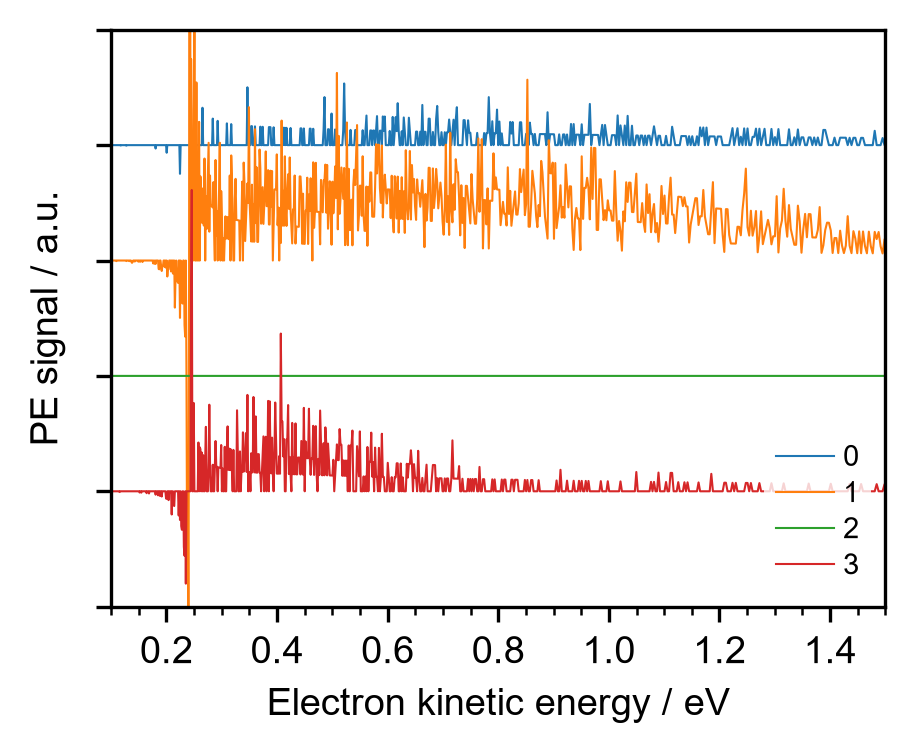

In [11]:
# Select one scan
# (doesn't matter which if they have all been recorded at the same time)

scan = scanSet[0]
# Select one delay (preferably one where the pump-probe signal is strong enough)
# Here ind the index of the time delay
ind= 6 #0 to (len(delays))-1


fig,ax = plt.subplots()
for i,spectrum in enumerate(scan.spectra[ind*4:ind*4+4]): # *4 as there are 4 spectra per delay
    print(f"{i}: {scan.delays[ind]} mm, tot counts: {np.sum(spectrum[1]):.0f}")
    ax.plot(spectrum[0],spectrum[1]-i*50, lw=.5, label=f"{i}")

ax.set_xlim(0.1,1.5)
ax.set_ylim(-200,50)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("PE signal / a.u.")
ax.set_yticklabels([])
ax.xaxis.set_major_locator(MultipleLocator(.2))
ax.xaxis.set_minor_locator(MultipleLocator(.05))

ax.legend(frameon=True,linewidth=0)
plt.show()

### Get subtracted spectra

In [12]:
# Here you subtract pump probe and nothing from pp by using the indices from above
# While the spectra are saved also saved as pps,pumps,probes and nothings
# the only important one is the first index as the others are all subtracted from it
for scan in scanSet:
    scan.subtract_background(1,3,0,2)

In [13]:
# plot one scan to check subtraction was successsful
scan = scanSet[0]
subtracted_rebinned = []
rebins = 10

for spectrum in scan.subtracted:
    spectrum = spectrum[:,np.logical_and(spectrum[0]>=.3,spectrum[0]<=5)]
    rebinned_spectrum = tr.reduceBins(spectrum,rebins)
    subtracted_rebinned.append(rebinned_spectrum)
subtracted_rebinned = np.array(subtracted_rebinned)


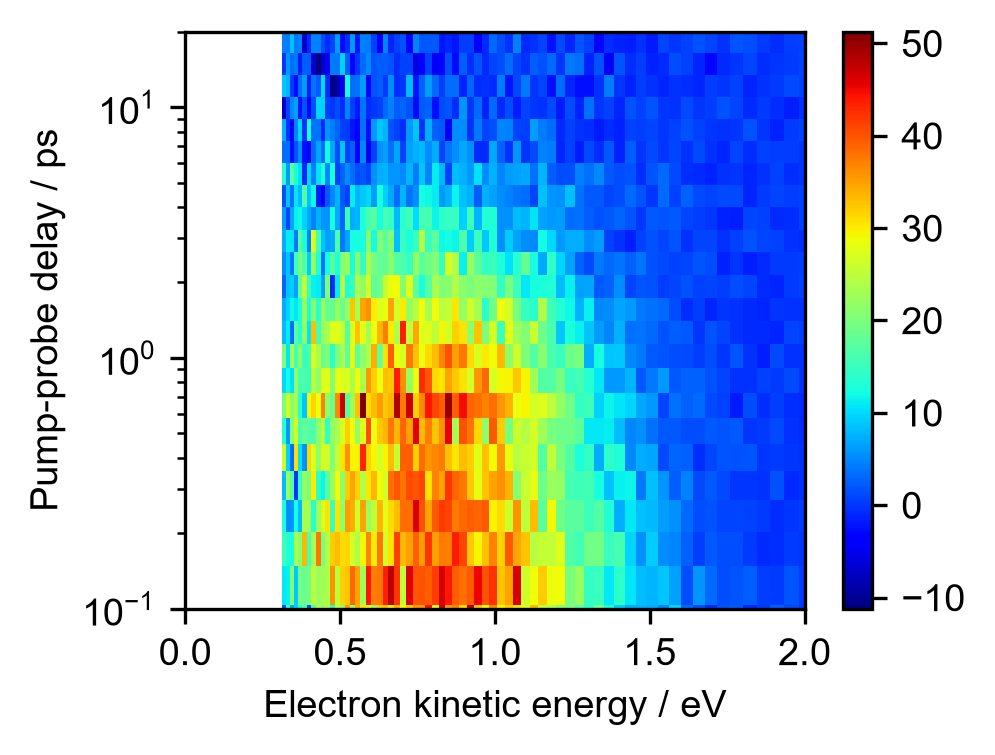

In [14]:
fig,ax = plt.subplots()
im0 = ax.pcolormesh(subtracted_rebinned[0,0],
                    scan.delayTimes,
                    subtracted_rebinned[:,1],
                    cmap='jet',
                    # shading='gouraud',
                   )

ax.set_yscale('log')
ax.set_xlim(0,2)
ax.set_ylim(.1,20)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")
plt.colorbar(im0)

### Add scanSets from same day

1. Remove data points below eKE cutoff and above 5 eV
2. Sum intensities for the same eKE and time delay (this can only be done if you didn't change the time points at any point & are using the same SP measurements)
3. Rebin data if you like

There is some confusion in the naming when it comes to summed and subtracted

In [15]:
# 1. Remove data points below low eKE cutoff and above 5 eV
for scan in scanSet:
    print(f"Min eKE: {scan.IFcutoff+scan.streamingPotentialCorrection:.4f} eV")
    scan.trim_energies()



Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV


In [16]:
# 2. Sum intensities for the same eKE and time delay
# (this can only be done if you didn't change the time points at any point
# & are using the same SP measurements)
scanSet.add_scans()

In [17]:
# 3. Rebin data every x bins if you like
rebins = 10
scanSet.rebin_subtracted_spectra(rebins)

### Plot heatmap of subtracted_rebinned

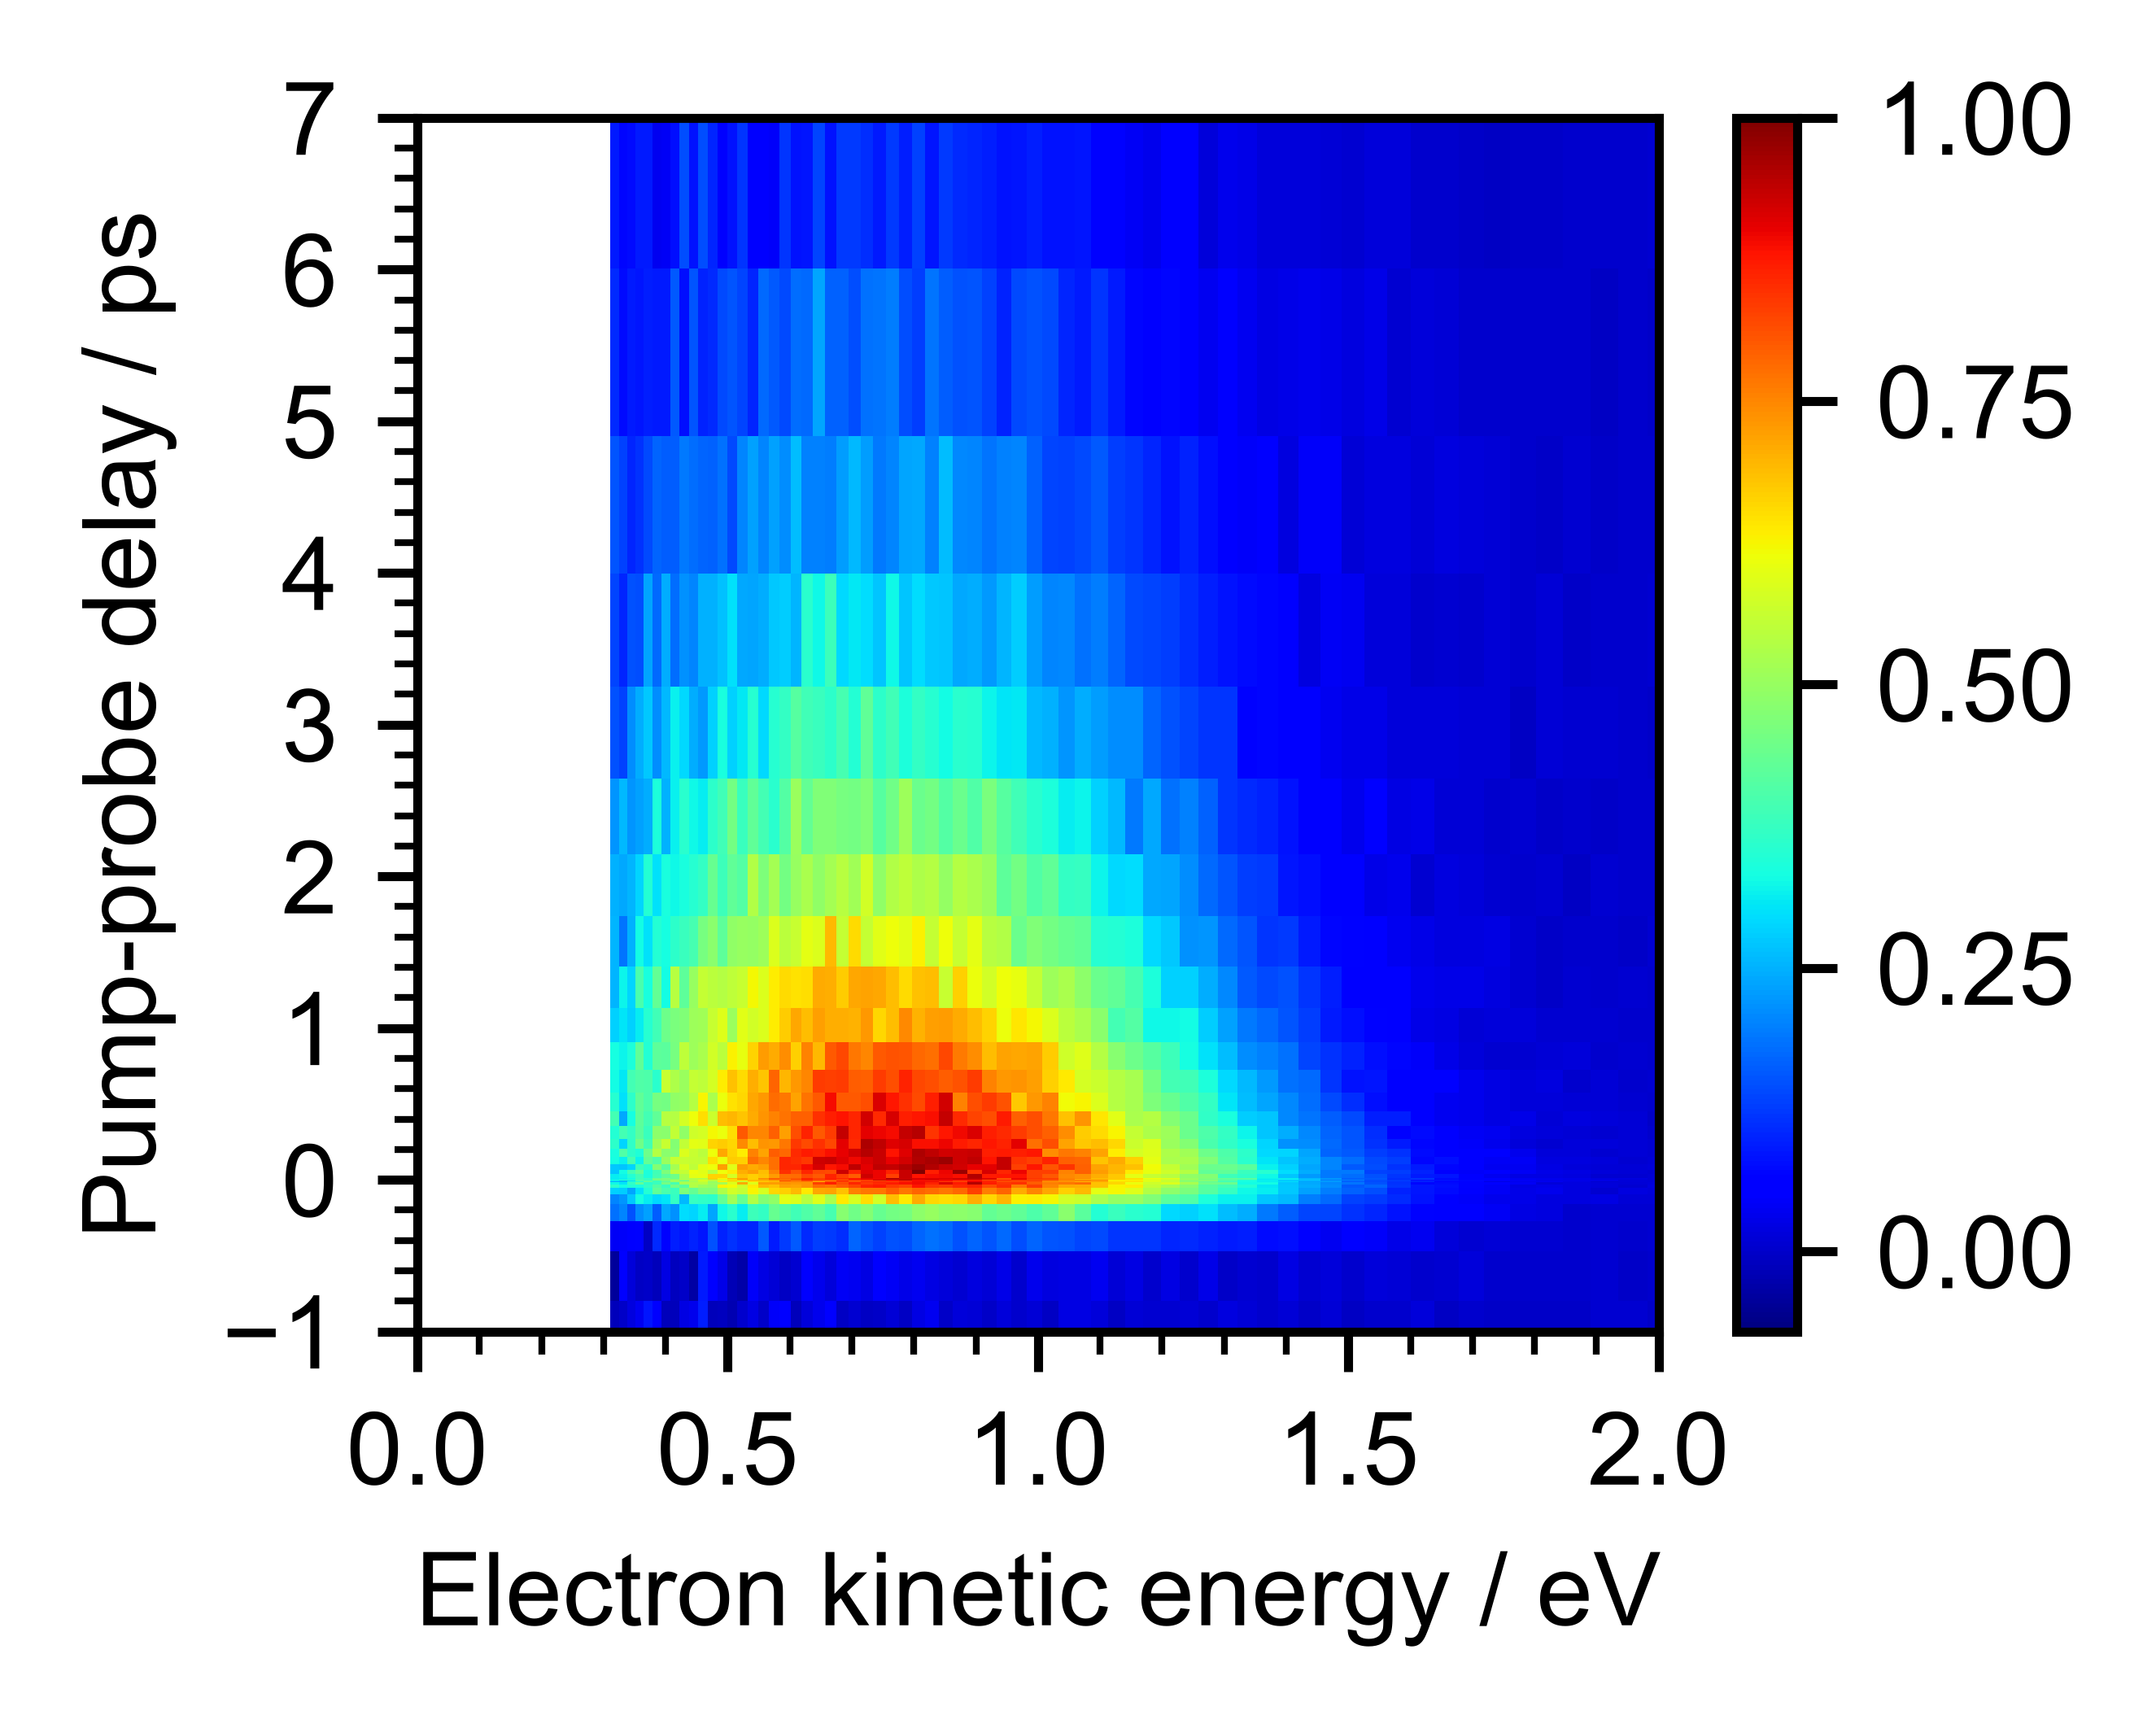

In [18]:
fig,ax = plt.subplots()
fig.set_dpi(1000)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)

im0 = ax.pcolormesh(scanSet.energies_rebinned,
                    scanSet.delays,
                    scanSet.subtracted_rebinned,
                    cmap='jet',
                    # shading='gouraud',

                   )


ax.set_xlim(0,2)
ax.set_ylim(-1,7)
# ax.set_yscale('log')
# ax.set_ylim(0.01,10)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax.yaxis.set_major_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(.2))
plt.colorbar(im0)

### Save data

In [19]:
# Save data
savepath = r"data/out/"
# Save unbinned data
save_arr = tr.create_save_arr(scanSet.energies,
                              scanSet.delays,
                              scanSet.subtracted)

np.savetxt(savepath+"ExperimentalData.csv",save_arr, delimiter = ',',fmt = "%.10e")


# Save binned data
save_arr = tr.create_save_arr(scanSet.energies_rebinned,
                              scanSet.delays,
                              scanSet.subtracted_rebinned)

np.savetxt(savepath+"RebinnedExperimentalData.csv",save_arr, delimiter = ',',fmt = "%.10e")

### Time-resolved data info

In [20]:
CROSS_CORRELATION = 0.320 #cross-correlation with 250 & 267
SIGMA = CROSS_CORRELATION / 2.355 
SIGMA

0.13588110403397027

### Find accurate time zero

Determine ```t0``` by fitting the total counts with a sum of exponential (here are 1 and 2) and find the value of ```t0```.

 ```Sigma = cross_correlation/2.335``` can be set to a specific value or floated. 

In [21]:
# Define delays for simplicity
delays = scanSet.delays
#Integrate spectra to get total counts at each delay
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)

#Make fit function with pre set SIGMA (you can also let it float if needed)
fit_func = lambda x,A1,tau1,t0: tr.monoexponential_witht0(x,A1,tau1,t0,SIGMA)

params,pcov=curve_fit(fit_func,scanSet.delays,trace,
                  p0=[0.8,1.8,0])
perr = np.sqrt(np.diag(pcov))

print("[A1, tau1, t0]")
print([float(f"{p:.4f}") for p in params])
print([float(f"{p:.4f}") for p in perr])

t0 = params[-1]
# Save t0 to scanSet?
scanSet.set_time_zero(params[-1])



[A1, tau1, t0]
[1.1131, 2.8306, -0.196]
[0.0058, 0.046, 0.0032]


A1, tau1, t0
[1.1131, 2.8306, -0.196]
[0.0058, 0.046, 0.0032]


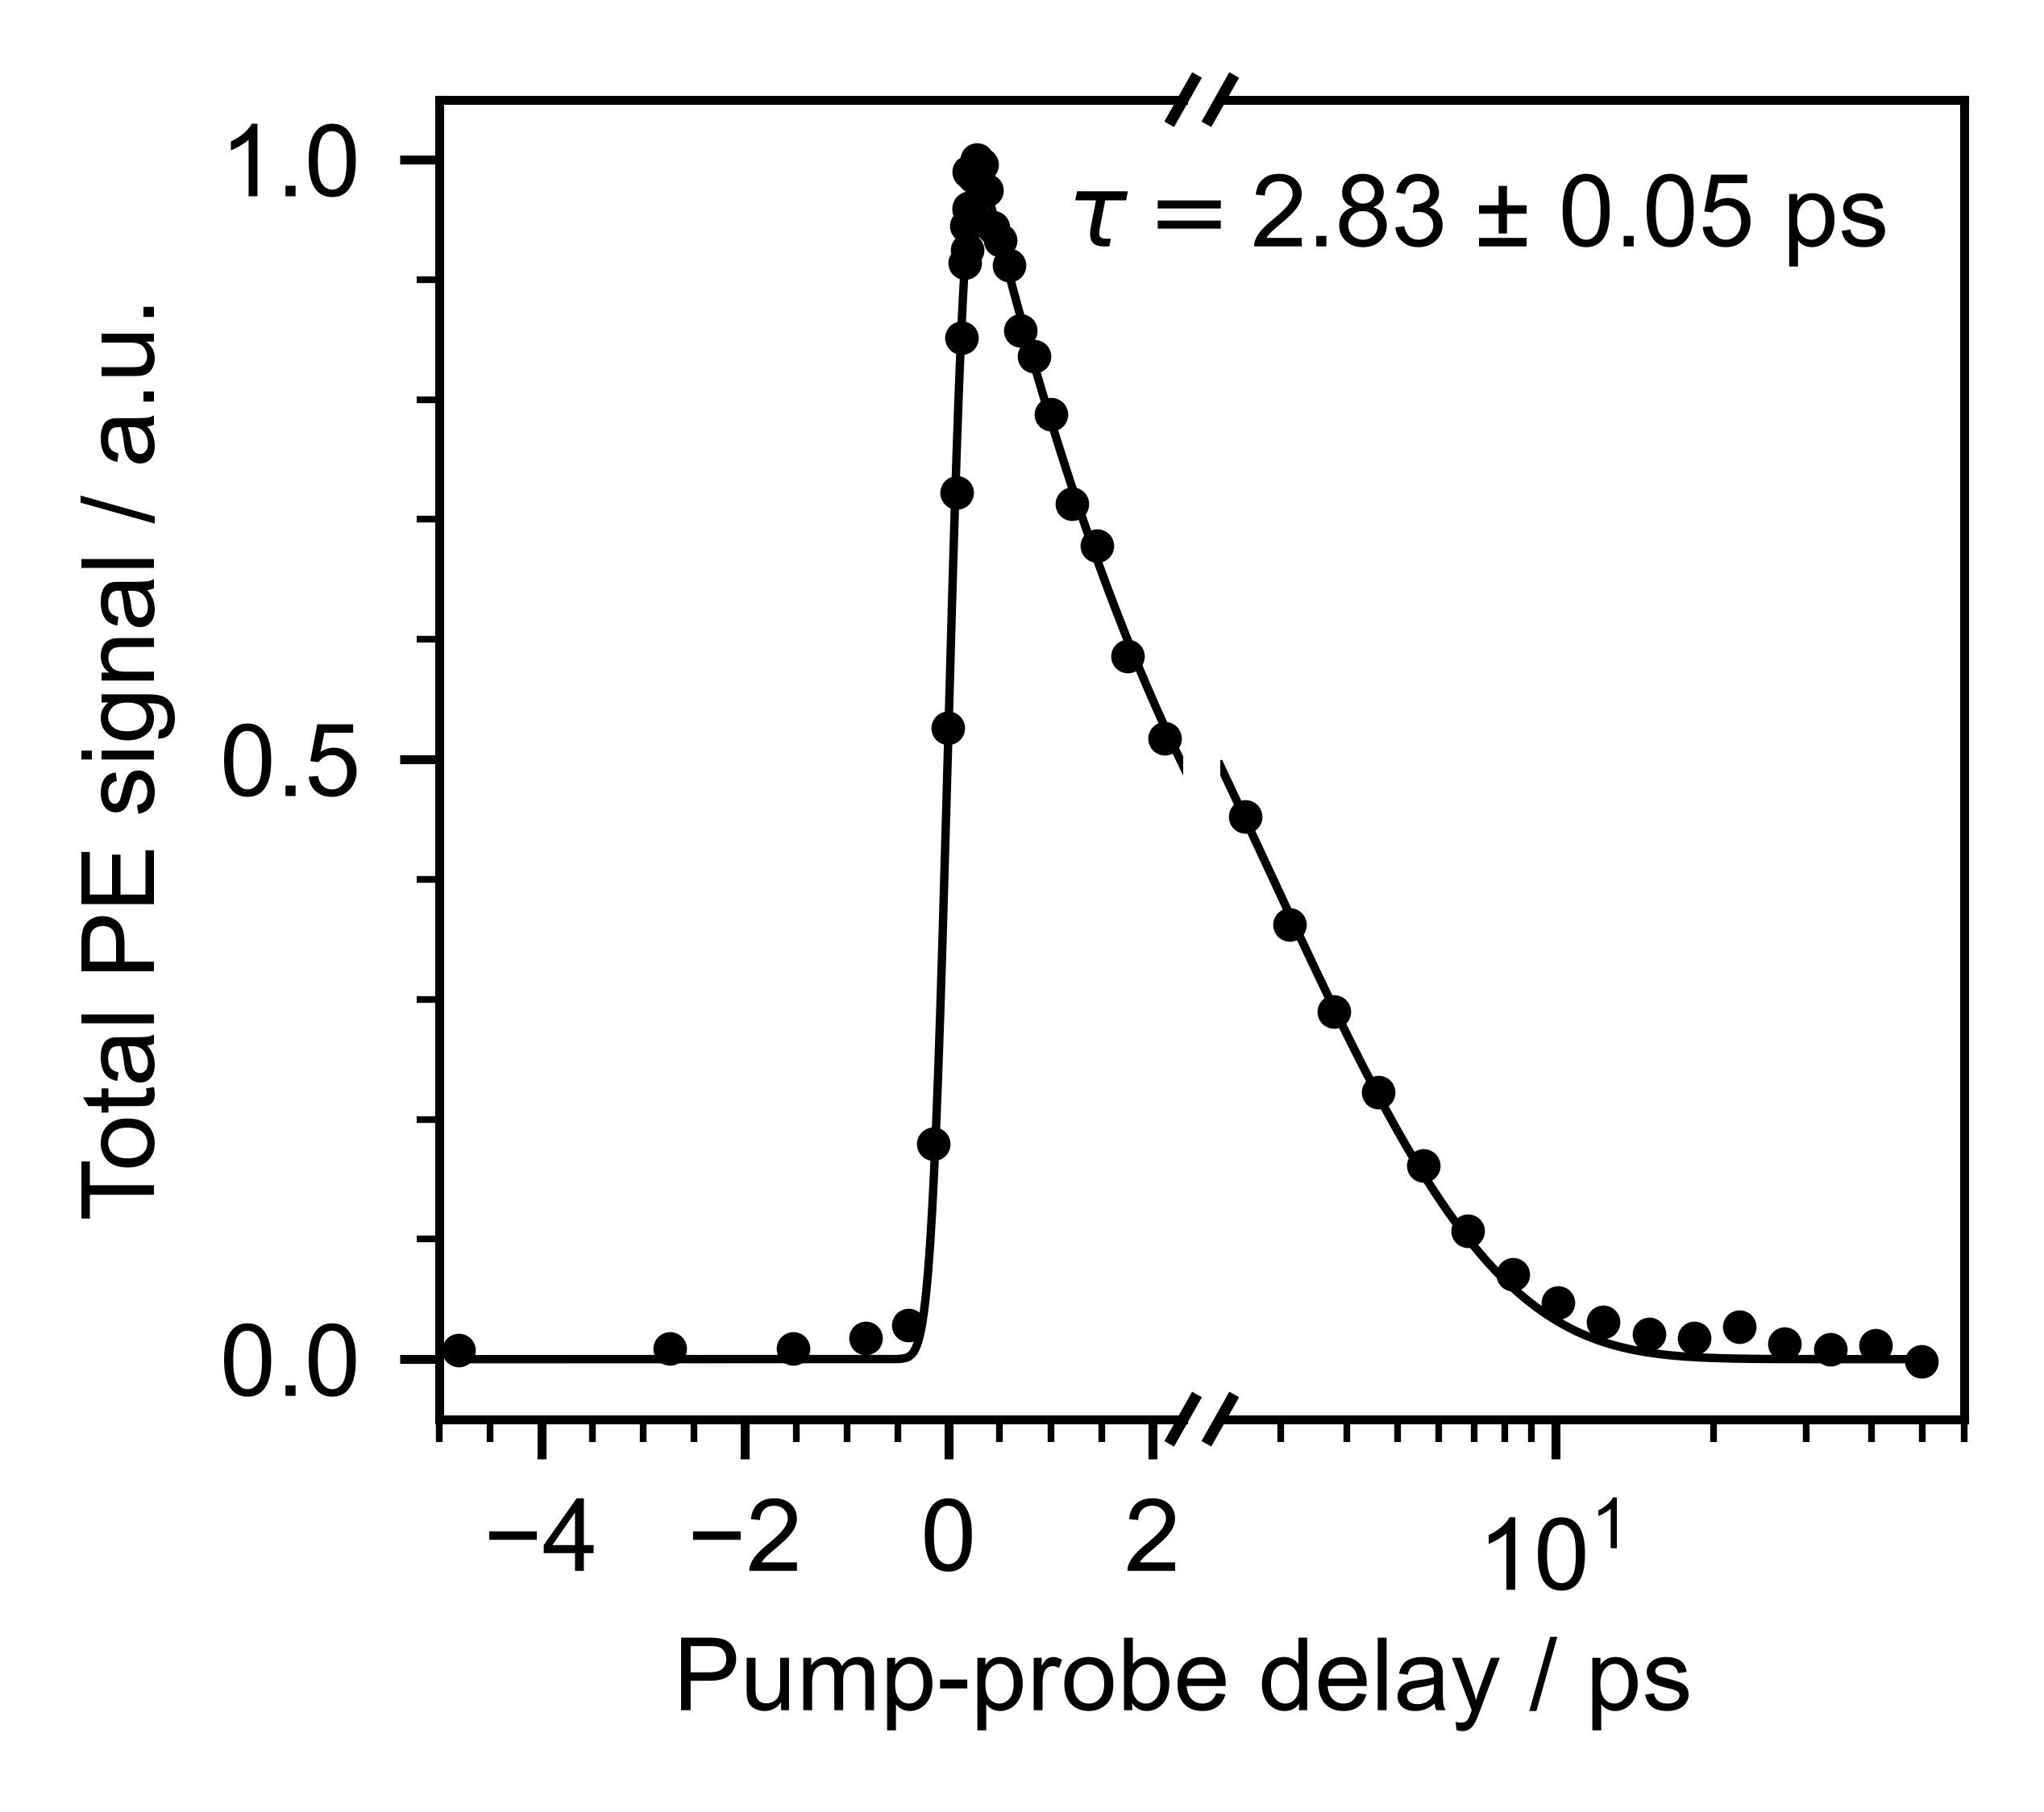

In [22]:
fig,axes = plt.subplots(1,2)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(1000)
fig.set_size_inches(15.5/2.5/2.54,13.5/2.5/2.54)
ax0,ax1 = axes
ts  =np.arange(-5,50,0.020)


for ax in axes:
    ax.plot(delays-t0,trace,'ko',ms=2,zorder=100)
    ax.plot(ts-t0,fit_func(ts,*params),'k',lw=.75)

print("A1, tau1, t0")
print([float(f"{p:.4f}") for p in params])
print([float(f"{p:.4f}") for p in perr])
ax0.set_xlim(-5,2.299)

ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)

for ax in axes:
    ax.set_ylim(-.05,1.05)
ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)

ax1.text(.9,.95,f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',va='top',transform=ax.transAxes)
   
    
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(.1))
ax0.xaxis.set_major_locator(MultipleLocator(2))
ax0.xaxis.set_minor_locator(MultipleLocator(.5))
ax1.xaxis.set_minor_formatter(NullFormatter())

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)      # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal

    
fig.patch.set_alpha(0)

In [23]:
# Check biexponential
fit_func = (lambda x,A1,tau1,A2,tau2,t0: 
            tr.monoexponential_witht0(x,A1,tau1,t0,SIGMA) +
            tr.monoexponential_witht0(x,A2,tau2,t0,SIGMA))

params,pcov=curve_fit(fit_func,delays,trace,
                  p0=[0.101, 0.443, 0.495, 2.047,0.066])
perr = np.sqrt(np.diag(pcov))

print("A1, tau1, A2, tau2,t0")
print([float(f"{p:.4f}") for p in params])
print([float(f"{p:.4f}") for p in perr])

t0 = params[0]

A1, tau1, A2, tau2,t0
[1.0885, 2.6717, 0.0305, 31.5495, -0.1944]
[0.0182, 0.0841, 0.0196, 32.206, 0.003]


A1, tau1, A2, tau2,t0
[1.089, 2.672, 0.031, 31.55, -0.194]
[0.018, 0.084, 0.02, 32.206, 0.003]


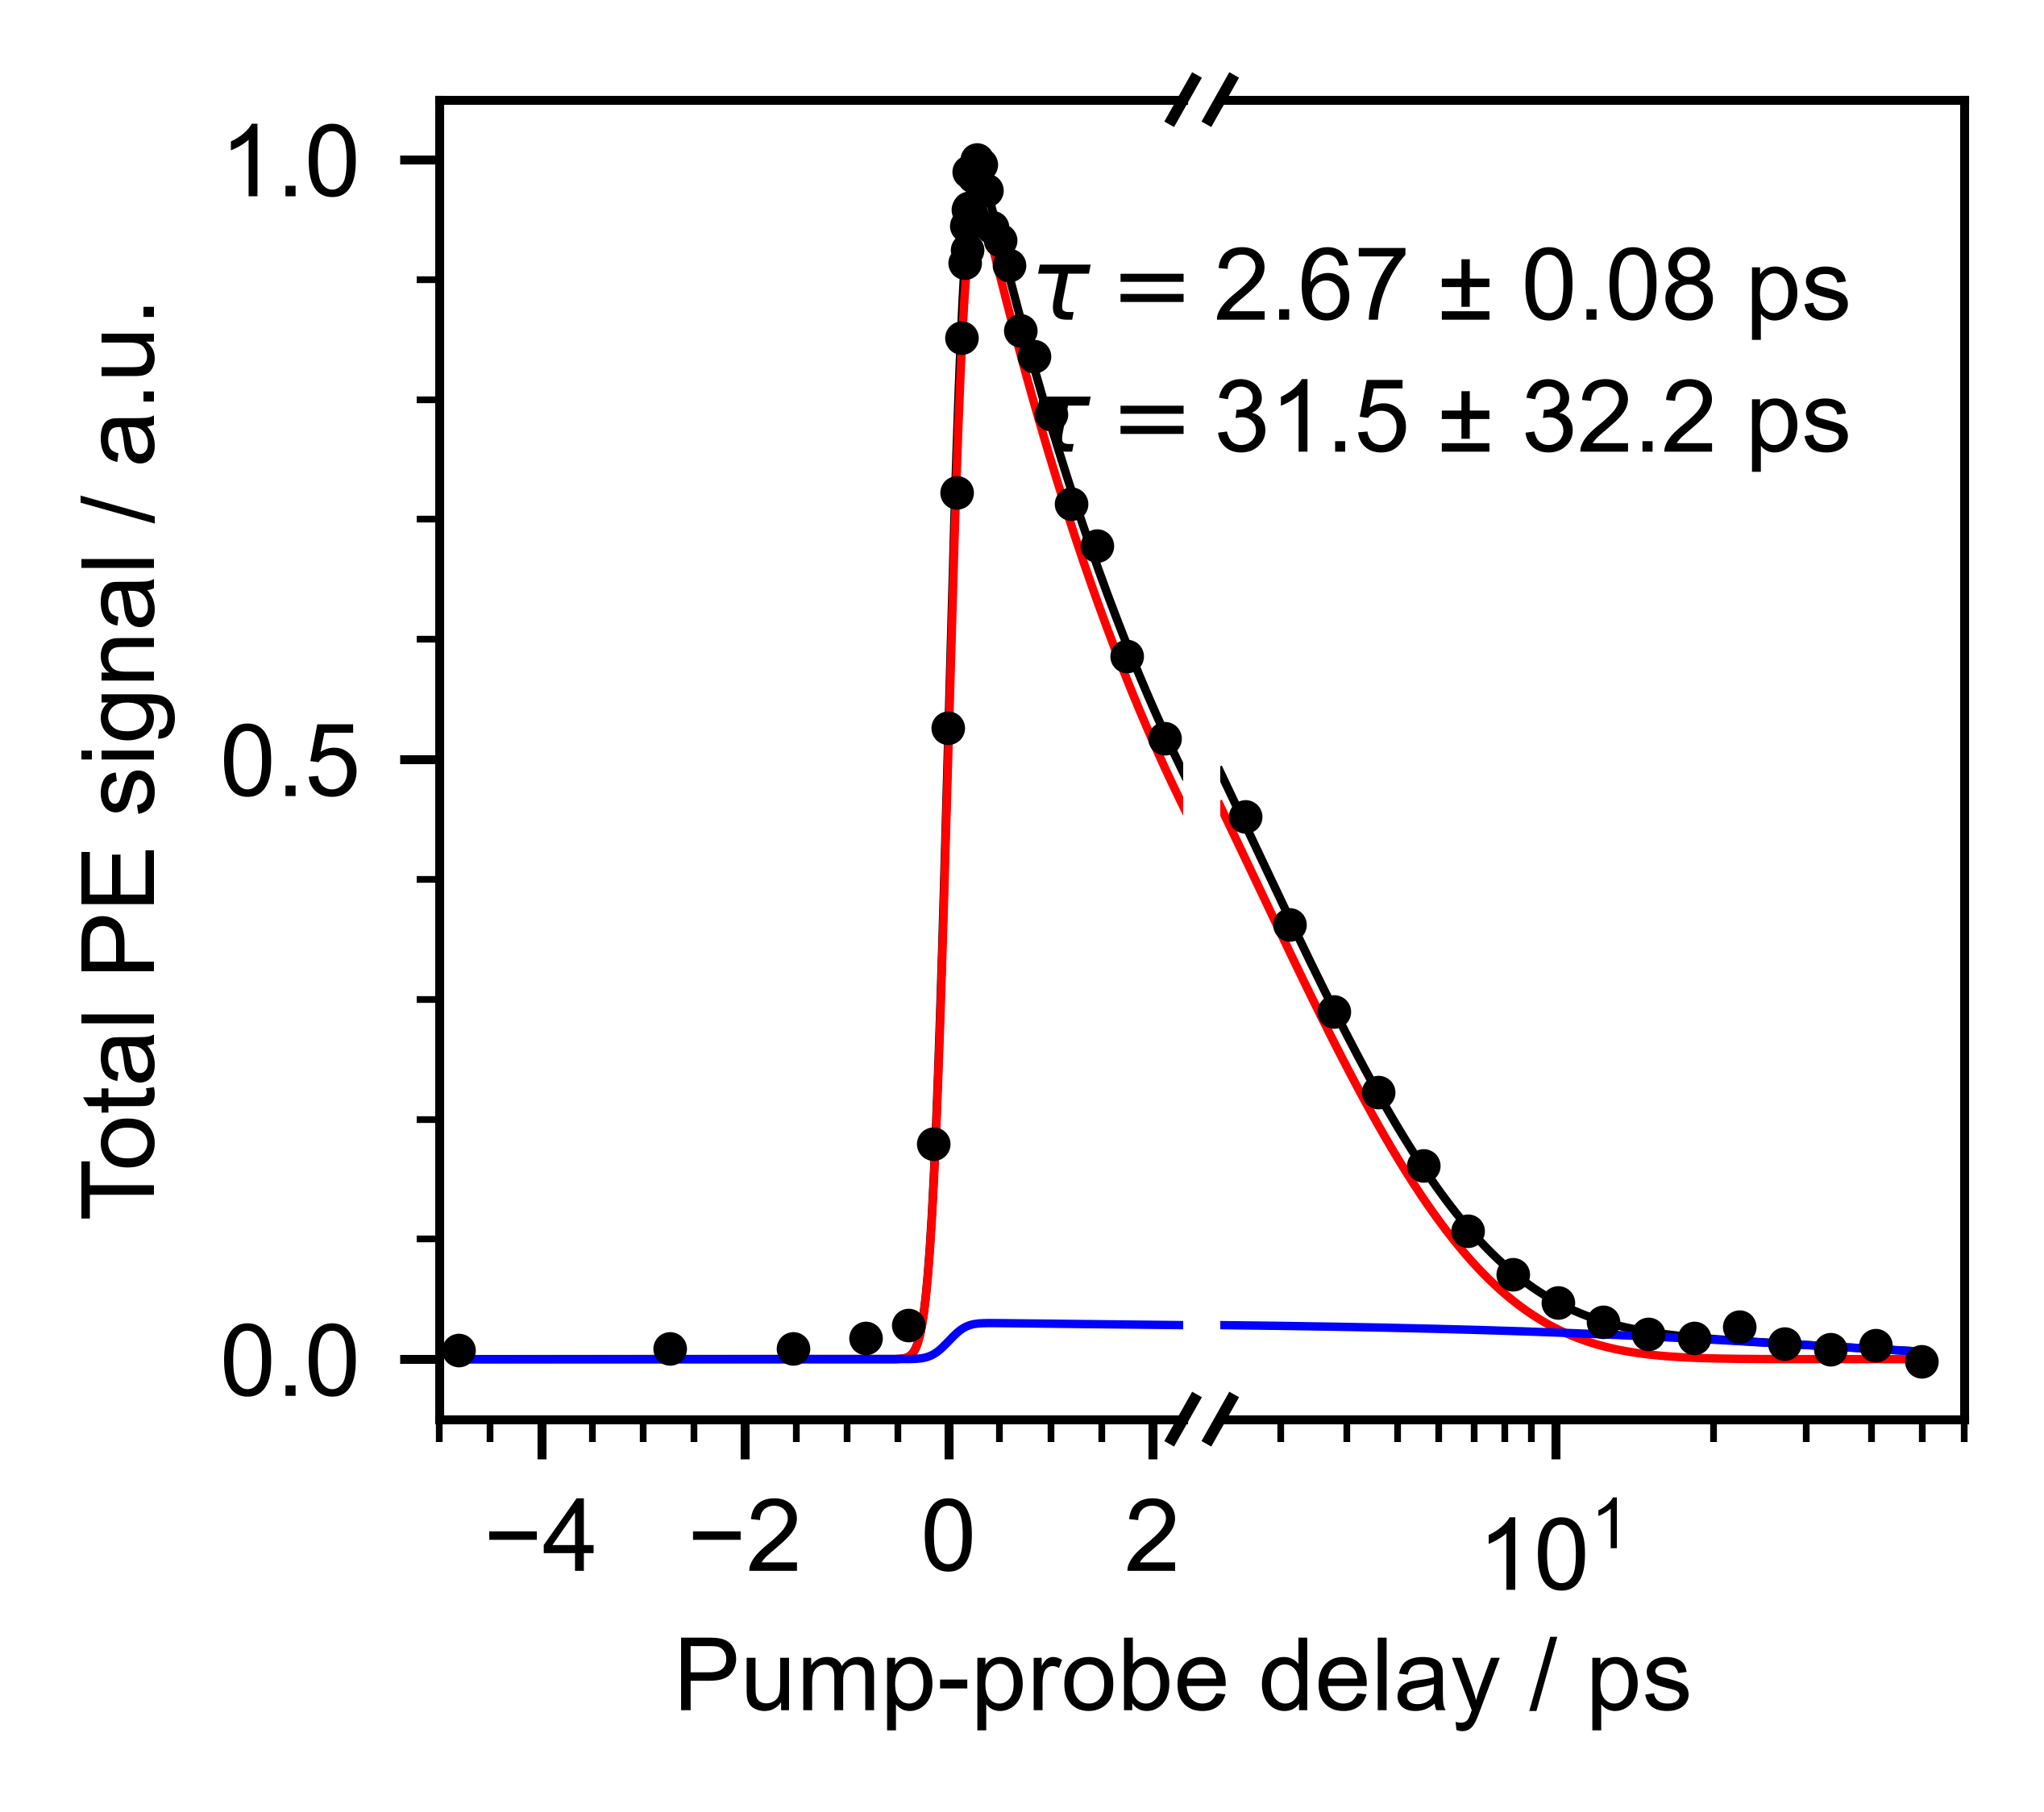

In [24]:
## biexponential
fig,axes = plt.subplots(1,2)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(1000)
fig.set_size_inches(15.5/2.5/2.54,13.5/2.54/2.5)
ax0,ax1 = axes
ts  =np.arange(-5,50,0.020)


t0 = params[-1]

for ax in axes:
    ax.plot(delays-t0,trace,'ko',ms=2,zorder=100)
    ax.plot(ts-t0,fit_func(ts,*params),'k',lw=.75)
    ax.plot(ts-t0,tr.monoexponential_witht0(ts,*params[:2],t0,SIGMA),'r',lw=.75)
    ax.plot(ts-t0,tr.monoexponential_witht0(ts,*params[2:4],t0,SIGMA),'b',lw=.75)
    
print("A1, tau1, A2, tau2,t0")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])
ax0.set_xlim(-5,2.299)

ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)

for ax in axes:
    ax.set_ylim(-.05,1.05)
ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)

ax1.text(.85,.75,f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',transform=ax.transAxes)
ax1.text(.85,.65,f"$\\tau =${params[3]:.1f} ± {perr[3]:.1f} ps\n",ha='right',transform=ax.transAxes)
   
    
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(.1))
ax0.xaxis.set_major_locator(MultipleLocator(2))
ax0.xaxis.set_minor_locator(MultipleLocator(.5))
ax1.xaxis.set_minor_formatter(NullFormatter())


# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal

    
fig.patch.set_alpha(0)

### Save data with t0

In [25]:
# Save with t0 as 0 ps
savepath = r"data/out/"
save_arr = tr.create_save_arr(scanSet.energies_rebinned,
                              scanSet.delays_t0,
                              scanSet.subtracted_rebinned)

np.savetxt(savepath+"SubtractedSpectra.csv",save_arr,delimiter=',', fmt = "%.10e")

### Transients

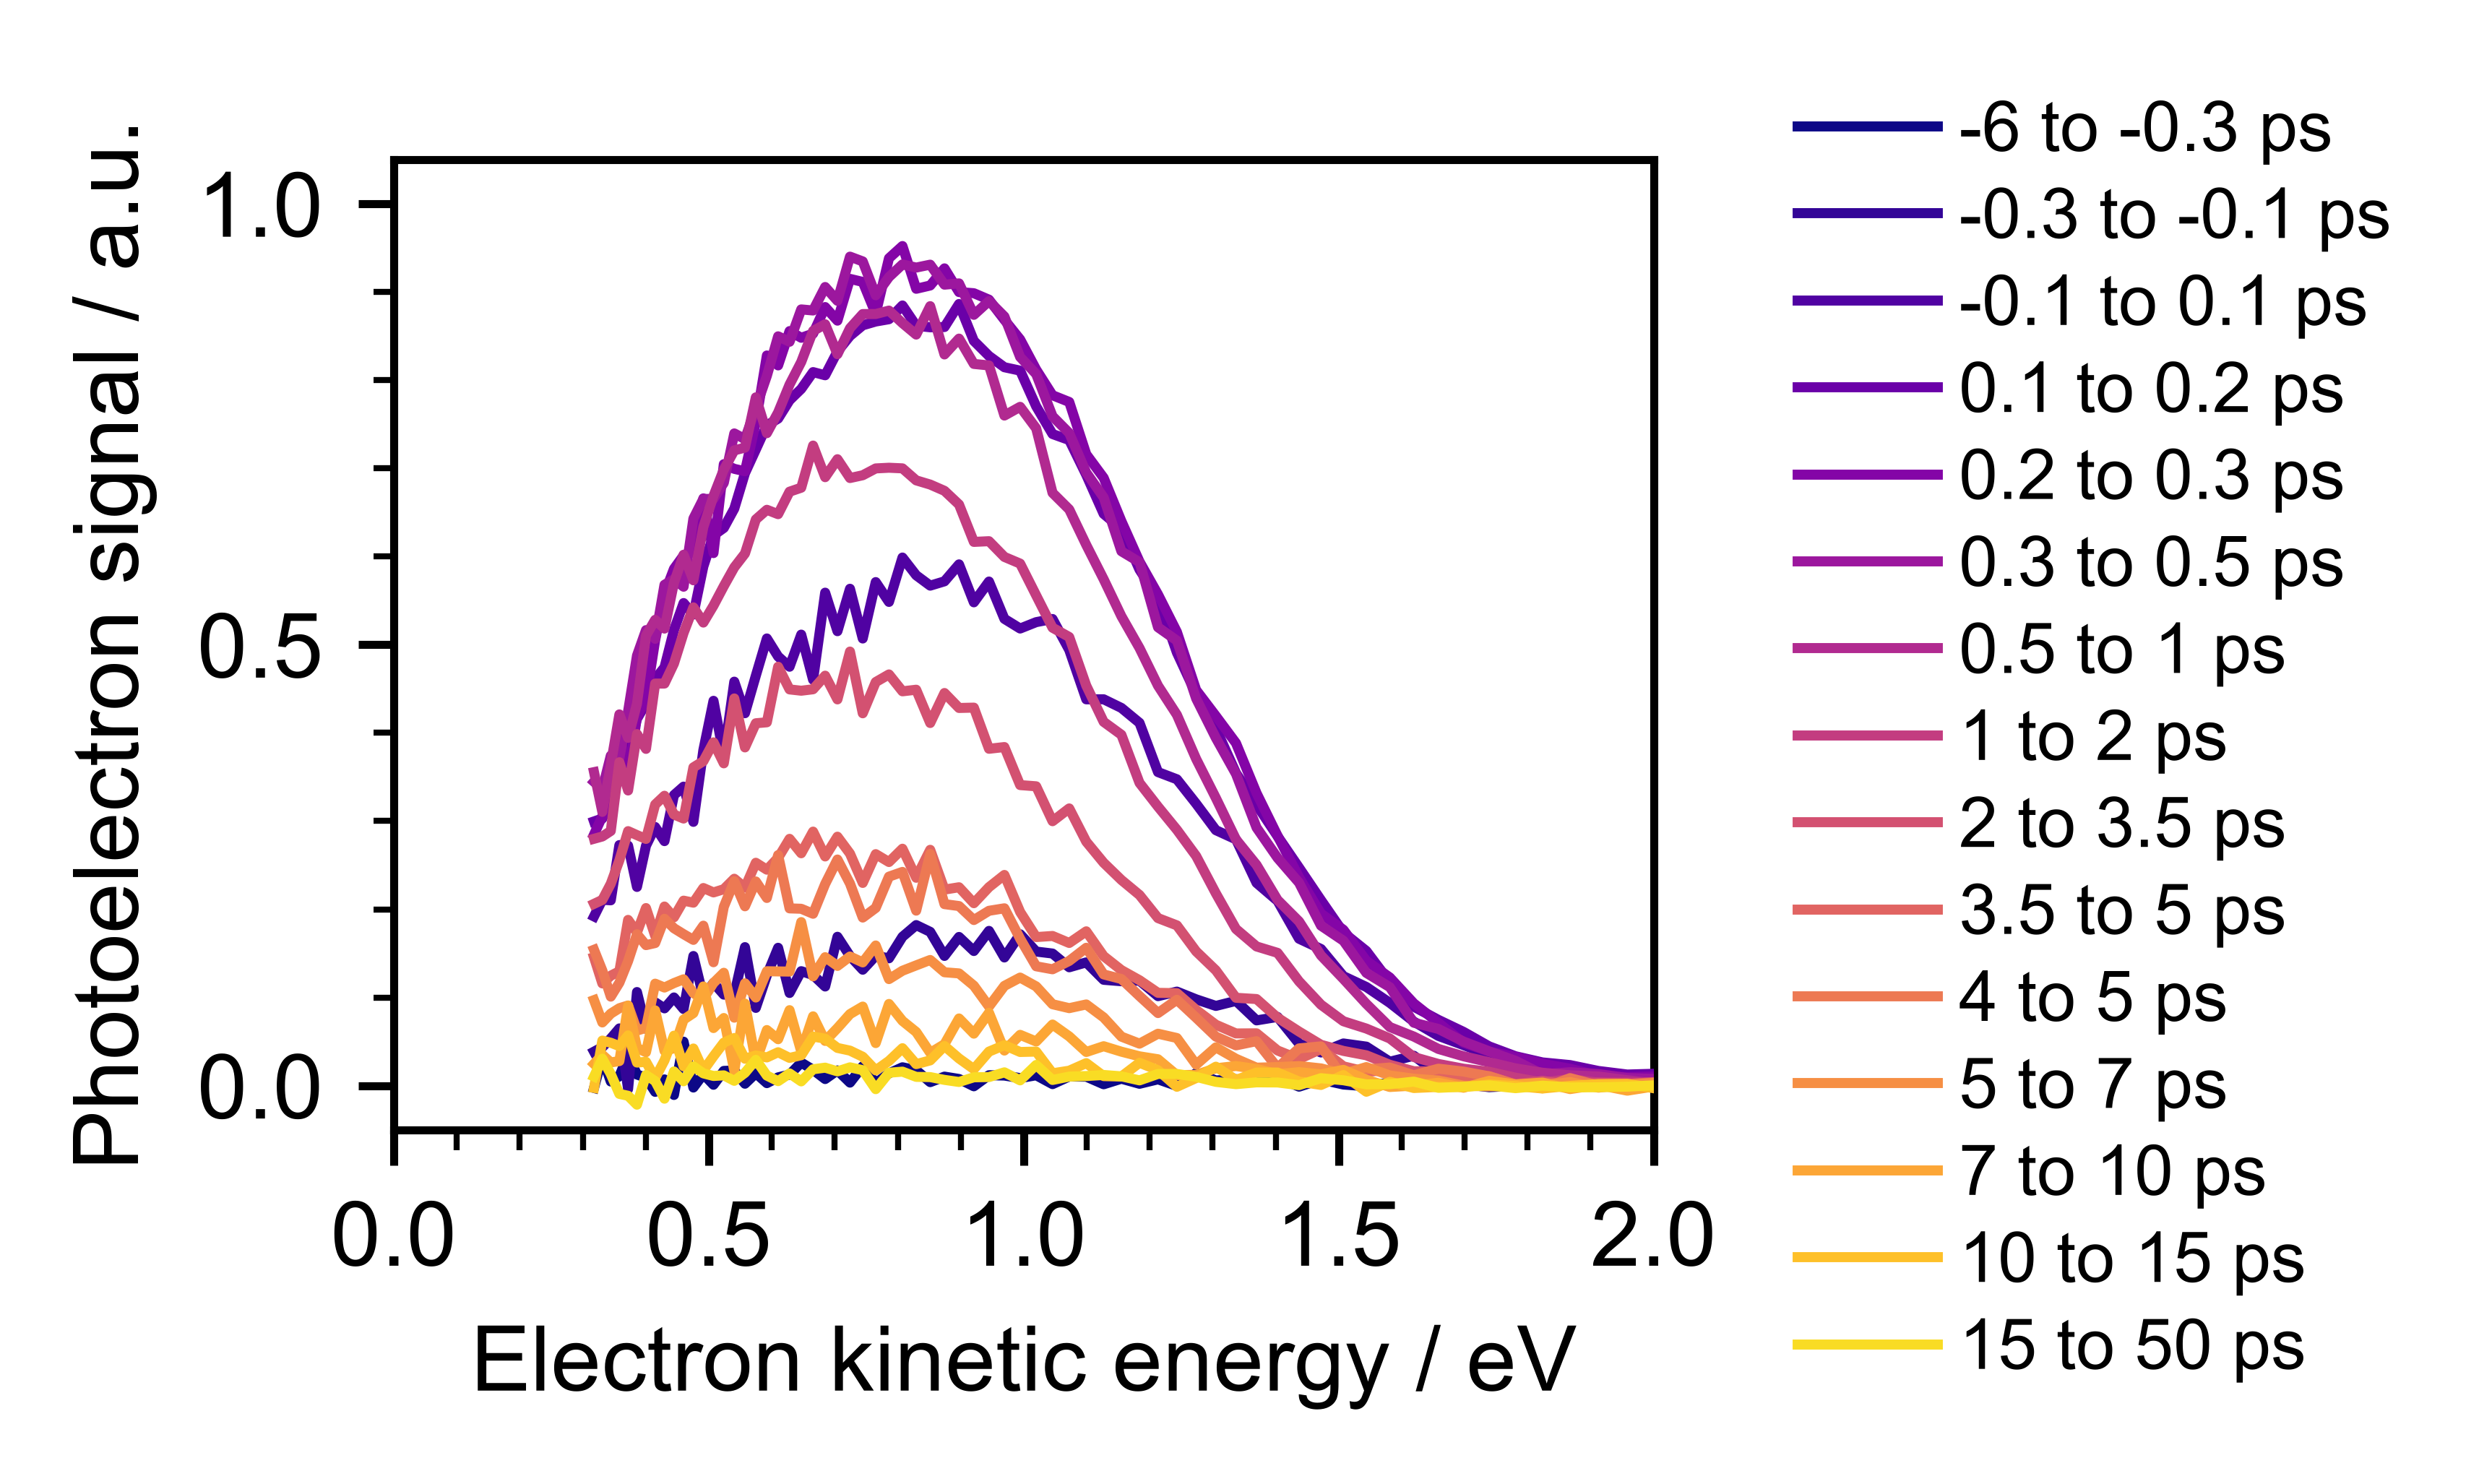

In [26]:
fig,ax = plt.subplots(1)
fig.set_dpi(1000)
fig.set_size_inches(20/3.5/2.54,15.5/2.54/3.5)

t0 = scanSet.t0
delays = scanSet.delays_t0

#Set limits for time ranges
timeRanges = [(-6,-.3),(-.3,-.1),(-.1,.1),(.1,.2),
              (.2,.3),(.3,.5),(.5,1),(1,2),(2,3.5),(3.5,5),(4,5),
              (5,7),(7,10),(10,15),(15,50),
             ]
#Create and normalise color map
cmap = plt.get_cmap('plasma')  # You can choose any colormap
norm = mcolors.Normalize(vmin=0, vmax=len(timeRanges))  # Normalize data from 0 to 100


for ind,timeRange in enumerate(timeRanges):
    #Mask data outside of time range
    mask = (np.logical_and(delays>timeRange[0],delays<=timeRange[1]))
    masked_data = scanSet.subtracted_rebinned[mask] 
    
    #Plot
    ax.plot(scanSet.energies_rebinned,np.mean(masked_data,axis=0),
            label = f"{timeRange[0]} to {timeRange[1]} ps",
            zorder=ind,
            c=cmap(norm(ind)),
           )

#Format
ax.set_xlim(0,2)
ax.set_ylim(-.05,1.05)

ax.set_ylabel("Photoelectron signal / a.u.")
ax.set_xlabel("Electron kinetic energy / eV")
    
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(.1))
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax.legend(frameon=False,bbox_to_anchor=[1.35, 0.4], 
           loc='center',ncol=1)

fig.patch.set_alpha(0)

## Retrieval spectra

### Load basis sets for retrieval

In [27]:
#Load retrieval functions
h5path = r"bases/"

fileDic = {
    "a": 0.0,
    "b": 0.1,
    "c": 0.2,
    "d": 0.3,
    "e": 0.5,
    "f": 0.8,
    "g": 1.0,
    "h": 1.5,
    "i": 2.0,
}
concAmps = [0.0,0.1,0.2,0.5,1.0,2.0,2.75,3.0,4.0,5.0,10.0,20.0,50.0,100.0]
concAmps = [0.0,0.1,0.2,0.5,1.0,2.0,         4.6,5.0,10.0,20.0,50.0,100.0]
E0s = list(fileDic.values())
crossSectionSets = ['1b','2','4','5']

#Guide for indices of basisSets (E0 amp)
indexGuide = []
for E0 in fileDic.values():
    indices = []
    for amp in concAmps:
        indices.append((E0, amp))
    indexGuide.append(indices)
indexGuide = np.array(indexGuide)

print("Loading basis sets...")
# Here I keep it open because it is very big file
h5File = h5py.File(h5path+'basisSets_pCE_2026.hdf5', 'r')
allBasisSets = h5File['allBasisSets']
allBasisSetsUnnorm = h5File['allBasisSetsUnnorm']
print("Basis sets loaded")

allBasisSets

Loading basis sets...
Basis sets loaded


<HDF5 dataset "allBasisSets": shape (4, 9, 12, 500, 500), type "<f8">

### Retrieve

NB: in ```rebinData``` y values are set to 0 if there is no data within two bins. Here, ```nanWarningSuppress``` is set to true because for this data set. This only happens above 4.10 eV where the data is ~0.
You must check what this lower limit is and that no data appears above this value for each data set by setting ```nanWarningSuppress```to false.
If you have data above this limit, you should interpolate the data or find another solution.

In [28]:
# Save results (and delays) in all_params and all_perrs with the following structure
# [
#   [delay, amp, centre, fwhm],
#             ...
# ]

Cross-section set: 1b
Escape threshold: 1.0 eV
Concentration profile G amplitude: 4.6
Type of gaussians: ['S']
--------
-0.150 ps [0.1025, 0.9983, 0.7991] [(7.19, 3.65)]
	G fit: [0.13, 0.88, 0.91]
-0.006 ps [0.3059, 0.9643, 0.8182] [(7.23, 3.68)]
	G fit: [0.39, 0.85, 0.91]
0.078 ps [0.4367, 0.9709, 0.7745] [(7.22, 3.68)]
	G fit: [0.54, 0.86, 0.88]


C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


0.127 ps [0.5197, 0.9577, 0.7819] [(7.23, 3.69)]
	G fit: [0.64, 0.85, 0.88]
0.157 ps [0.565, 0.9473, 0.7805] [(7.24, 3.7)]
	G fit: [0.69, 0.84, 0.87]
0.173 ps [0.5911, 0.9535, 0.7666] [(7.24, 3.7)]
	G fit: [0.72, 0.84, 0.87]
0.183 ps [0.5747, 0.9483, 0.776] [(7.24, 3.7)]
	G fit: [0.7, 0.84, 0.87]
0.189 ps [0.5797, 0.9495, 0.7865] [(7.24, 3.7)]
	G fit: [0.71, 0.84, 0.88]
0.193 ps [0.5912, 0.9465, 0.7861] [(7.24, 3.7)]
	G fit: [0.73, 0.84, 0.87]
0.195 ps [0.5937, 0.9364, 0.7926] [(7.26, 3.71)]
	G fit: [0.73, 0.83, 0.88]
0.196 ps [0.6077, 0.9389, 0.7944] [(7.25, 3.71)]
	G fit: [0.75, 0.83, 0.87]
0.218 ps [0.6037, 0.9406, 0.7727] [(7.25, 3.71)]
	G fit: [0.74, 0.83, 0.86]
0.245 ps [0.6148, 0.9405, 0.7833] [(7.25, 3.71)]
	G fit: [0.75, 0.83, 0.87]
0.279 ps [0.6377, 0.9401, 0.7671] [(7.25, 3.71)]
	G fit: [0.78, 0.83, 0.85]
0.319 ps [0.638, 0.9318, 0.7714] [(7.26, 3.72)]
	G fit: [0.77, 0.82, 0.86]
0.369 ps [0.6285, 0.9206, 0.7783] [(7.27, 3.73)]
	G fit: [0.76, 0.82, 0.86]
0.430 ps [0.6209, 0.9

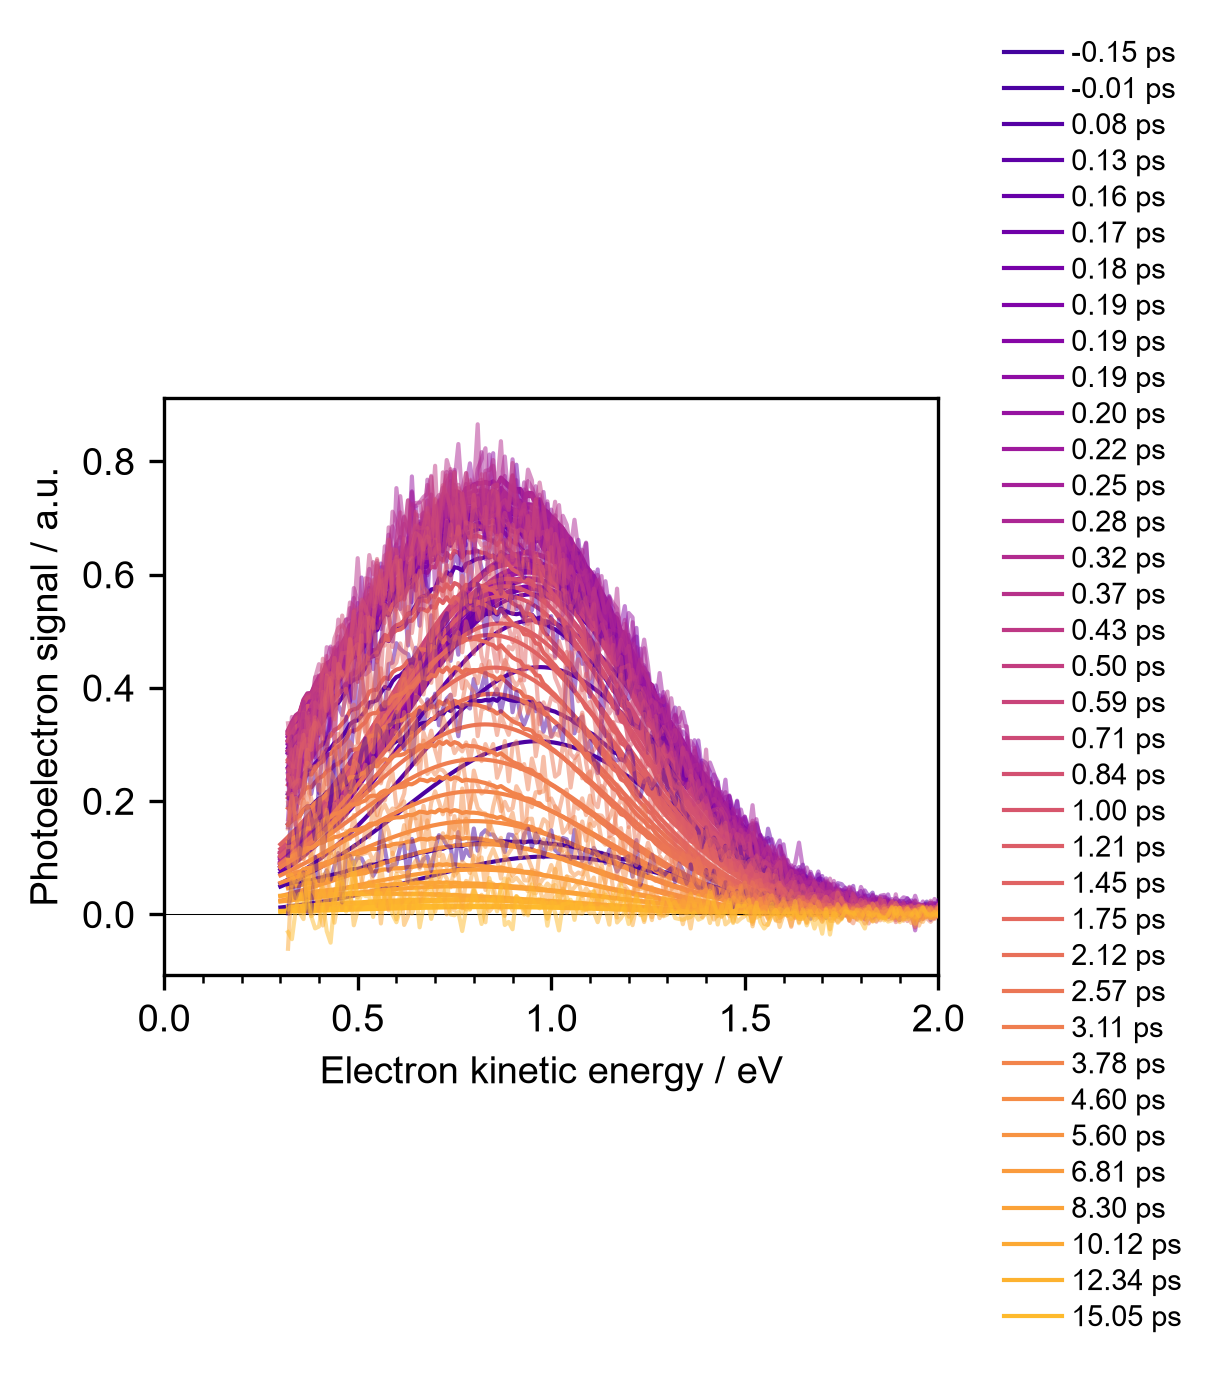

In [29]:
fig,ax = plt.subplots(1)
# ax0,ax1 = axes

#Retrieval parameters
all_params = [] 
all_perrs = [] 
#Gaussian fit parameters
all_params_gau = [] 
all_perrs_gau = [] 

#t0
t0 = scanSet.t0

xs = np.arange(0.01,5.01,0.01)
crossSectionSetInd = 0
thresholdInd = 6
surfInd = 6
gauss_types = ['S']

print(f"Cross-section set: {crossSectionSets[crossSectionSetInd]}")
print(f"Escape threshold: {E0s[thresholdInd]} eV")
print(f"Concentration profile G amplitude: {concAmps[surfInd]}")
print(f"Type of gaussians: {gauss_types}")
print('-'*8)

cmap = plt.get_cmap('plasma')  # You can choose any colormap
norm = mcolors.Normalize(vmin=0, vmax=len(scanSet.delays_t0))  # Normalize data 

# Change range to include more or less spectra.
# Those at negative and long delays will not fit so they
# are usually excluded
for ind in range(5,41): 

    fittableData = np.array((scanSet.energies,
                             scanSet.subtracted[ind]))

    #----------RETRIEVE-----------
    # Pick surface and bulk basis functions 
    surf_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,surfInd]
    bulk_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,0]
    surf_bas /= np.amax(surf_bas)

    #Rebin data onto 0.01 eV grid and cutoff below low eKE cutoff
    min_eKE = min(fittableData[0])
    rebinnedData = rebinData(fittableData,min_eKE,nanWarningSuppress=True)
    x_above_cutoff,y_above_cutoff = rebinnedData

    #Create fit functions with basis functions and min_eKE
    fitfunc = JetFitFunc(gauss_types, surf_bas, bulk_bas, min_eKE)
    #Fit
    params,pcov = curve_fit(fitfunc.f, xs, y_above_cutoff,
                             p0 = [1,.9,1],
                             bounds = (0,np.inf)
                             )
    #Get errors of fit
    perrs = np.sqrt(np.diag(pcov))

    #Plot data
    ax.plot(x_above_cutoff,y_above_cutoff,
            zorder=ind,
            c=cmap(norm(ind)),
            alpha=.5
           )

    #Plot fit
    ax.plot(x_above_cutoff, fitfunc.f(xs, *params),
            c=cmap(norm(ind)),
            label = f"{scanSet.delays_t0[ind]:.2f} ps",
           )
    #Plot retrieval
    ax.plot(spectrum[0],multiple_gaussians(spectrum[0],*params),
            c=cmap(norm(ind)))

    
    print(f"{scanSet.delays_t0[ind]:.3f} ps",[float(f"{p:.4f}") for p in params], end=' ')
    # print([float(f"{p:.3f}") for p in params[1::3]])
    print([(float(f"{1239.8/350 + 1239.8/266.67 - p:.2f}"),float(f"{1239.8/266.67 - p:.2f}")) for p in params[1::3]])
    all_params.append([scanSet.delays_t0[ind],]+list(params))
    all_perrs.append([scanSet.delays_t0[ind],]+list(perrs))

    #-----------------Fit GAUSSIAN---------------
    params,pcov= curve_fit(multiple_gaussians,
                        fittableData[0],fittableData[1],
                        p0 = [1,.9,1],
                       bounds=[0,np.inf])
    perrs = np.sqrt(np.diag(pcov))
    all_params_gau.append([scanSet.delays_t0[ind],]+list(params))
    all_perrs_gau.append([scanSet.delays_t0[ind],]+list(perrs))
    print("\tG fit:", [float(f"{p:.2f}") for p in params])

all_params = np.array(all_params)
all_perrs = np.array(all_perrs)
all_params_gau = np.array(all_params_gau)
all_perrs_gau = np.array(all_perrs_gau)

ax.hlines(0,0,5,'k',lw=.25)

ax.set_xlim(0,2)

ax.set_ylabel("Photoelectron signal / a.u.")
ax.set_xlabel("Electron kinetic energy / eV")
    
# ax.yaxis.set_major_locator(MultipleLocator(.5))
# ax.yaxis.set_minor_locator(MultipleLocator(.1))
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax.legend(frameon=False,bbox_to_anchor=[1.2, 0.5], 
           loc='center')


### Create datasets of retrieved spectra and the fits to the spectra

In [30]:
# Initialise arrays
# Set of fits to spectra (cut off at x cutoff)
scanSet.subtracted_fit = np.zeros((len(all_params),len(x_above_cutoff)))
# Set of retrieved spectra (cut off at x cutoff)
scanSet.subtracted_retrieved = np.zeros((len(all_params),len(x_above_cutoff)))
# Set of retrieved spectra (including below x cutoff)
scanSet.subtracted_retrieved_full = np.zeros((len(all_params),len(xs)))

for i,params in enumerate(all_params):
    # Fit
    scanSet.subtracted_fit[i] = fitfunc.f(xs, *params[1:])
    # Retrieved above cutoff
    scanSet.subtracted_retrieved[i] = multiple_gaussians(x_above_cutoff, *params[1:])  
    # Retrieved full
    scanSet.subtracted_retrieved_full[i] = multiple_gaussians(xs, *params[1:])  

#Normalise dataset as absolute intensity is already scaled
scanSet.subtracted_retrieved/=np.amax(scanSet.subtracted_retrieved)
#Normalise dataset as absolute intensity is already scaled
scanSet.subtracted_retrieved_full/=np.amax(scanSet.subtracted_retrieved_full)

#Save delays of retrieved/fit spectra
scanSet.delays_retrieved = all_params[:,0]
#Save eKEs of retrieved/fit spectra
scanSet.energies_retrieved = x_above_cutoff
scanSet.energies_retrieved_full = xs
# Save fit parameters
scanSet.params_retrieved = all_params[:,1:]

In [31]:
# Create dataset of data rebinned onto grid

scanSet.subtracted_grid = np.zeros((len(scanSet.delays_t0),len(x_above_cutoff)))

for i,ind in enumerate(range(len(scanSet.delays_t0))): 
    fittableData = np.array((scanSet.energies,
                             scanSet.subtracted[ind]))
    min_eKE = min(fittableData[0])
    rebinnedData = rebinData(fittableData,min_eKE,
                             nanWarningSuppress=True)
    # some values above 4.10 eV are 'nan' and have been set to 0. 
    # As the signal is ~ 0 here we do not care


    scanSet.subtracted_grid[i] = rebinnedData[1]


### Plots of retrieved data

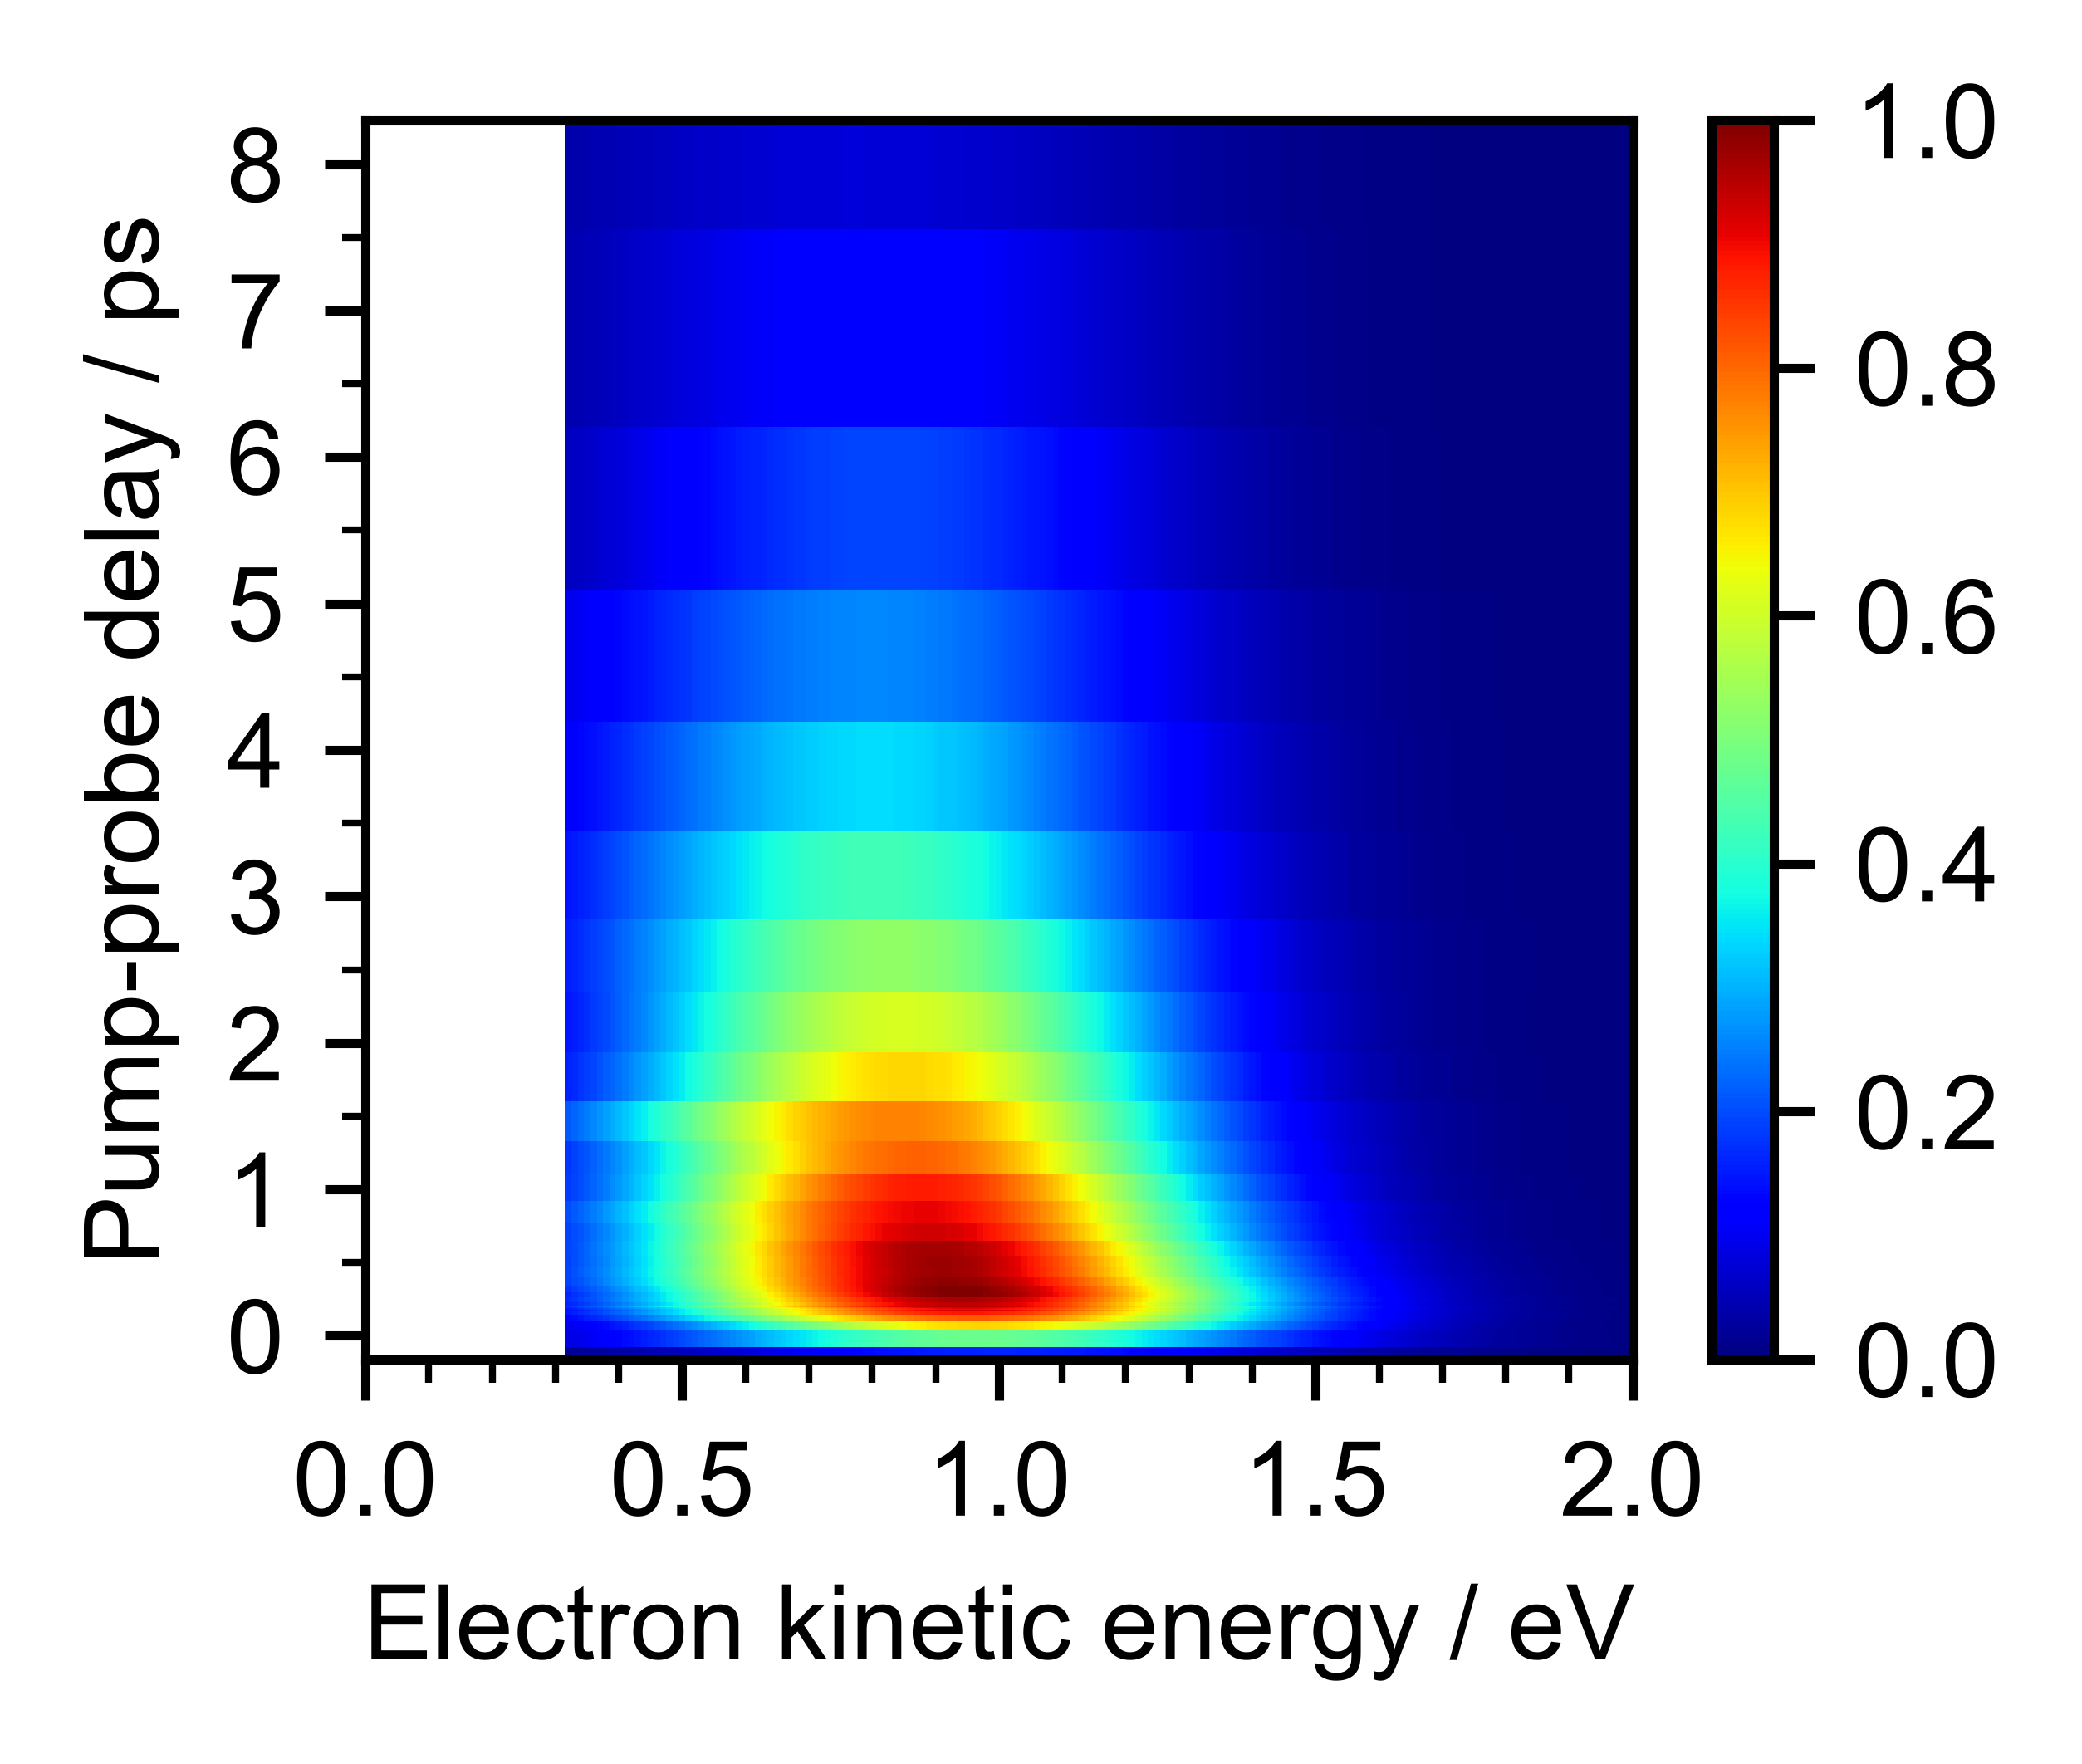

In [32]:
fig,ax = plt.subplots()
fig.set_dpi(1000)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)


im0 = ax.pcolormesh(scanSet.energies_retrieved,
                    scanSet.delays_retrieved,
                    scanSet.subtracted_retrieved,
                    cmap='jet',
                    # shading='gouraud',
                    vmin=0
                   )

# Plot mean eKE
# ax.plot(scanSet.params_retrieved[:,1],
#         scanSet.delays_retrieved,
#         'o-',c='w',ms=1,alpha=1,
#         label='Mean eKE')


ax.set_xlim(0,2)
ax.set_ylim(-0.16,8.3)
# ax.set_yscale('log')
# ax.set_ylim(0.06,18)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax.yaxis.set_major_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(.5))
plt.colorbar(im0)

#### Fit heatmap

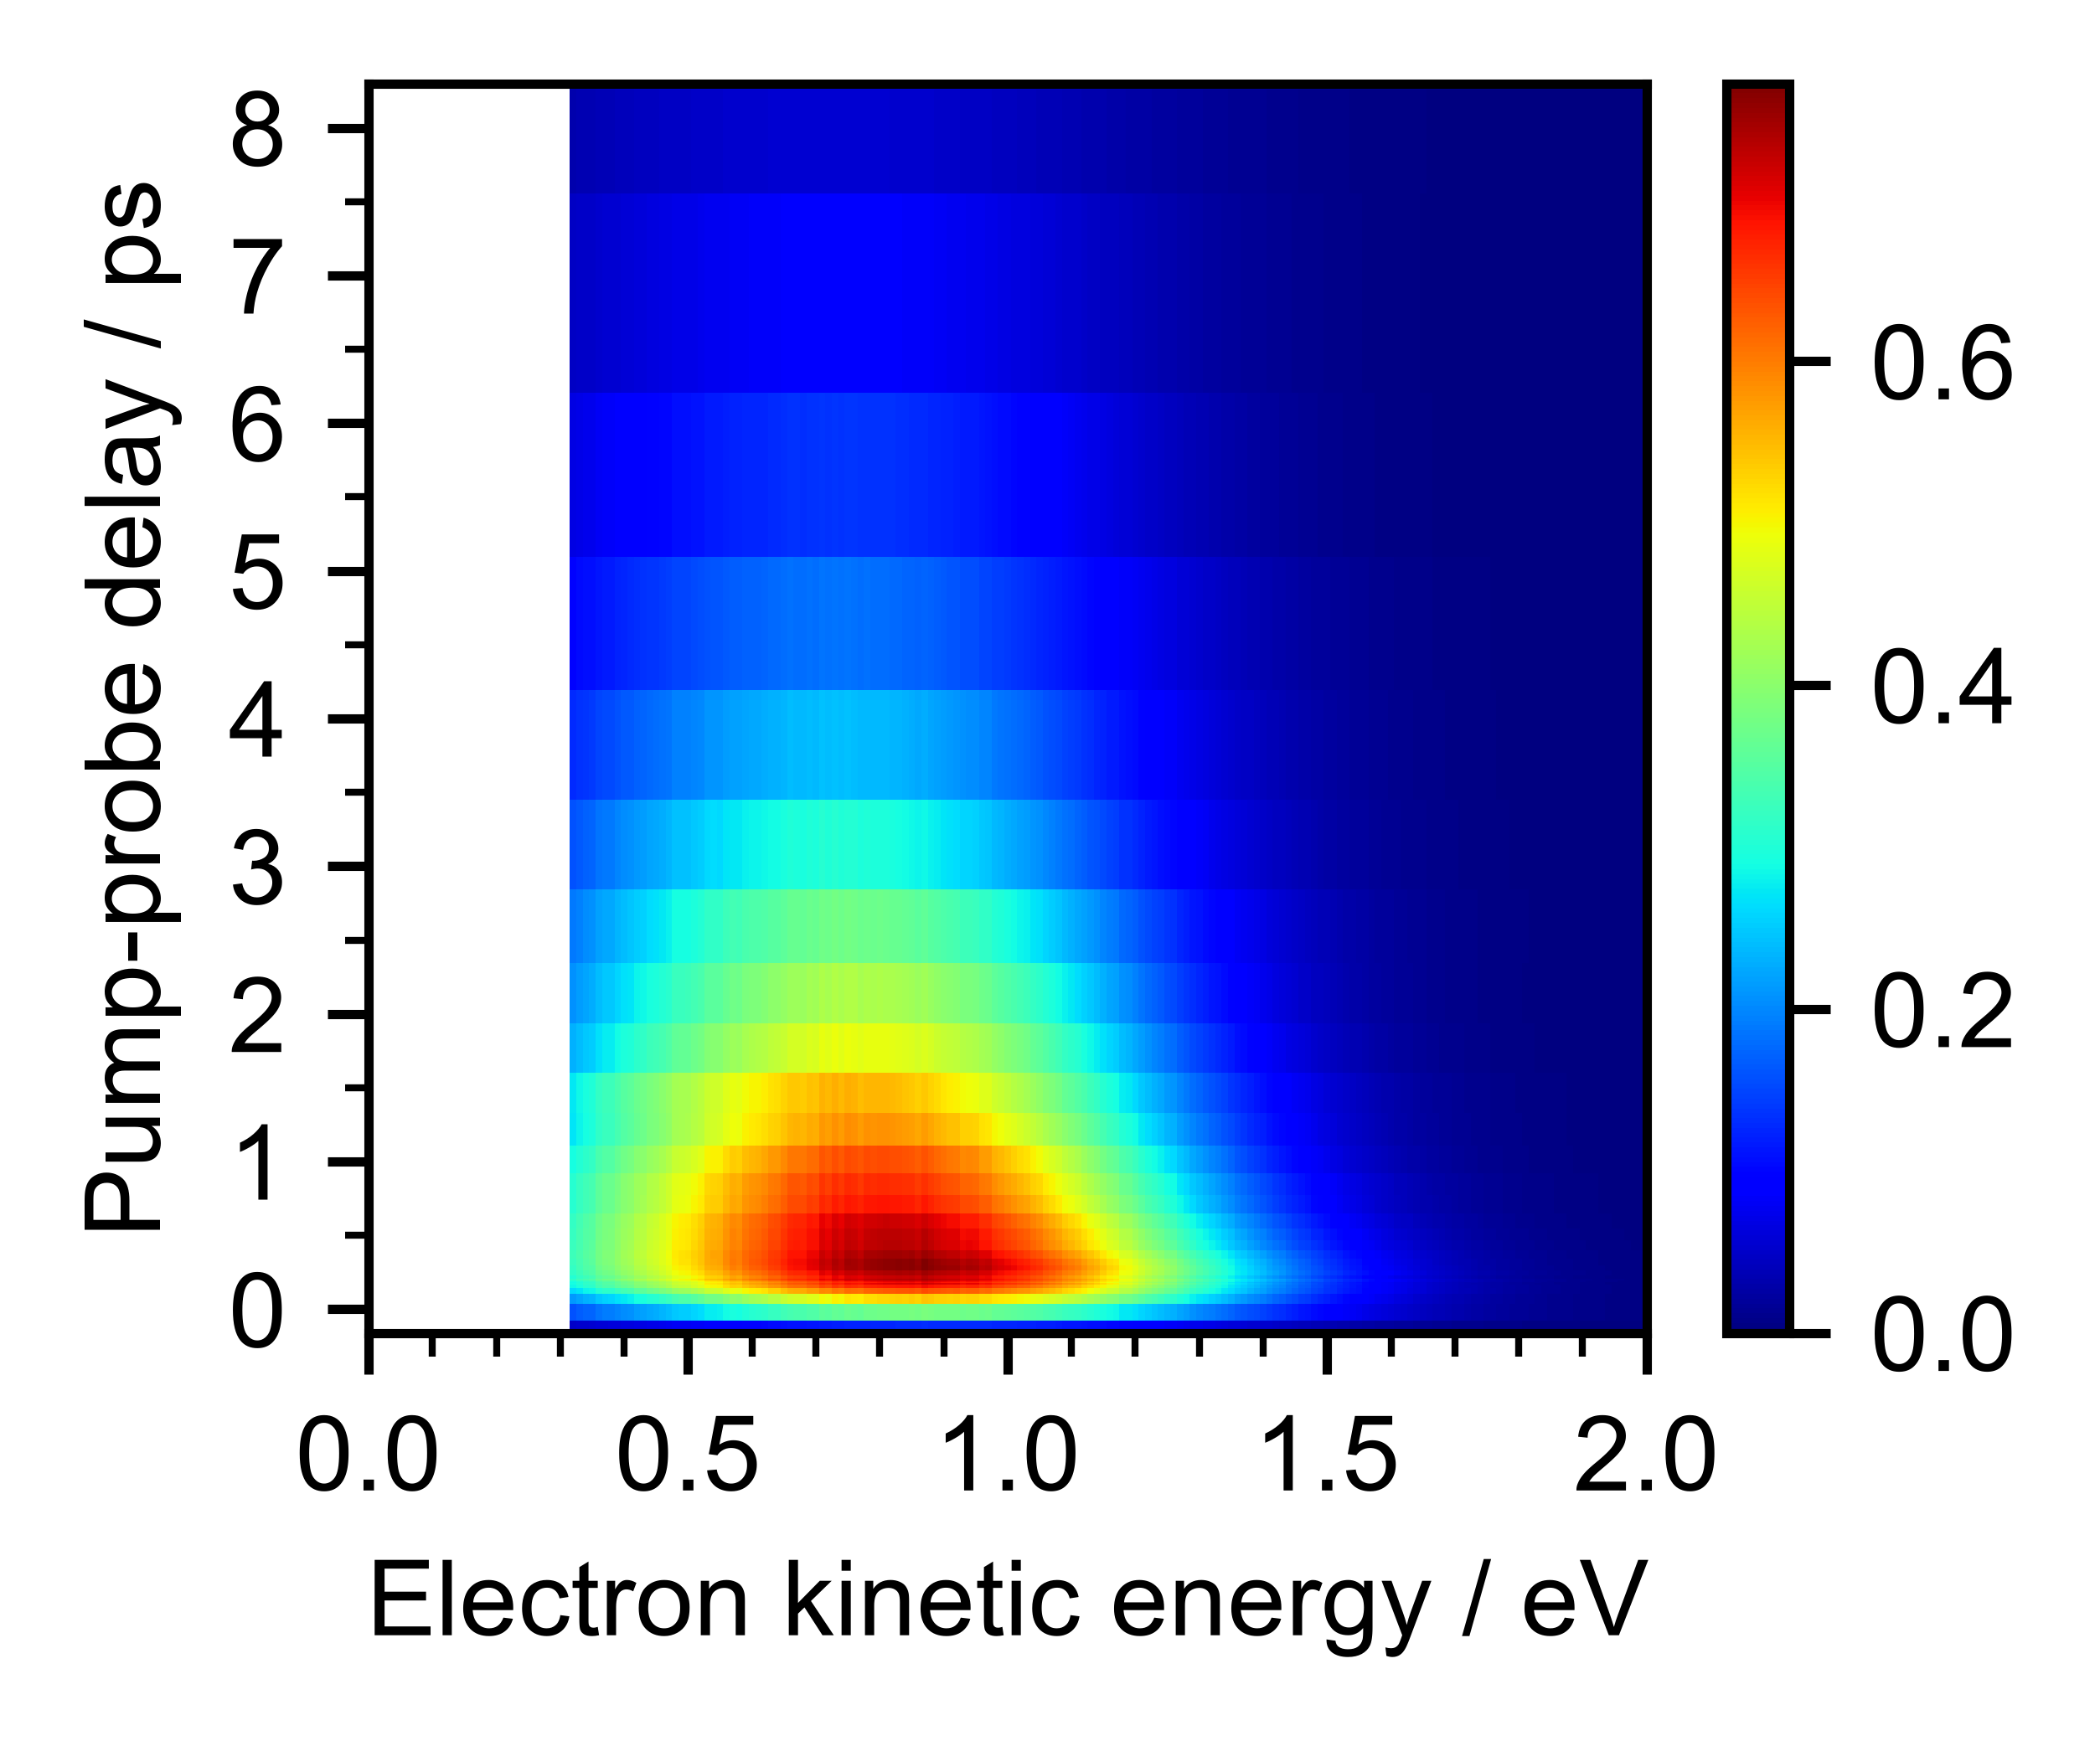

In [33]:
fig,ax = plt.subplots()
fig.set_dpi(1000)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)


im0 = ax.pcolormesh(scanSet.energies_retrieved,
                    scanSet.delays_retrieved,
                    scanSet.subtracted_fit,
                    cmap='jet',
                    # shading='gouraud',
                    # vmin=-1
                   )


ax.set_xlim(0,2)
ax.set_ylim(-0.16,8.3)
# ax.set_yscale('log')
# ax.set_ylim(0.06,18)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax.yaxis.set_major_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(.5))
plt.colorbar(im0)

#### Rebinned onto grid heatmap

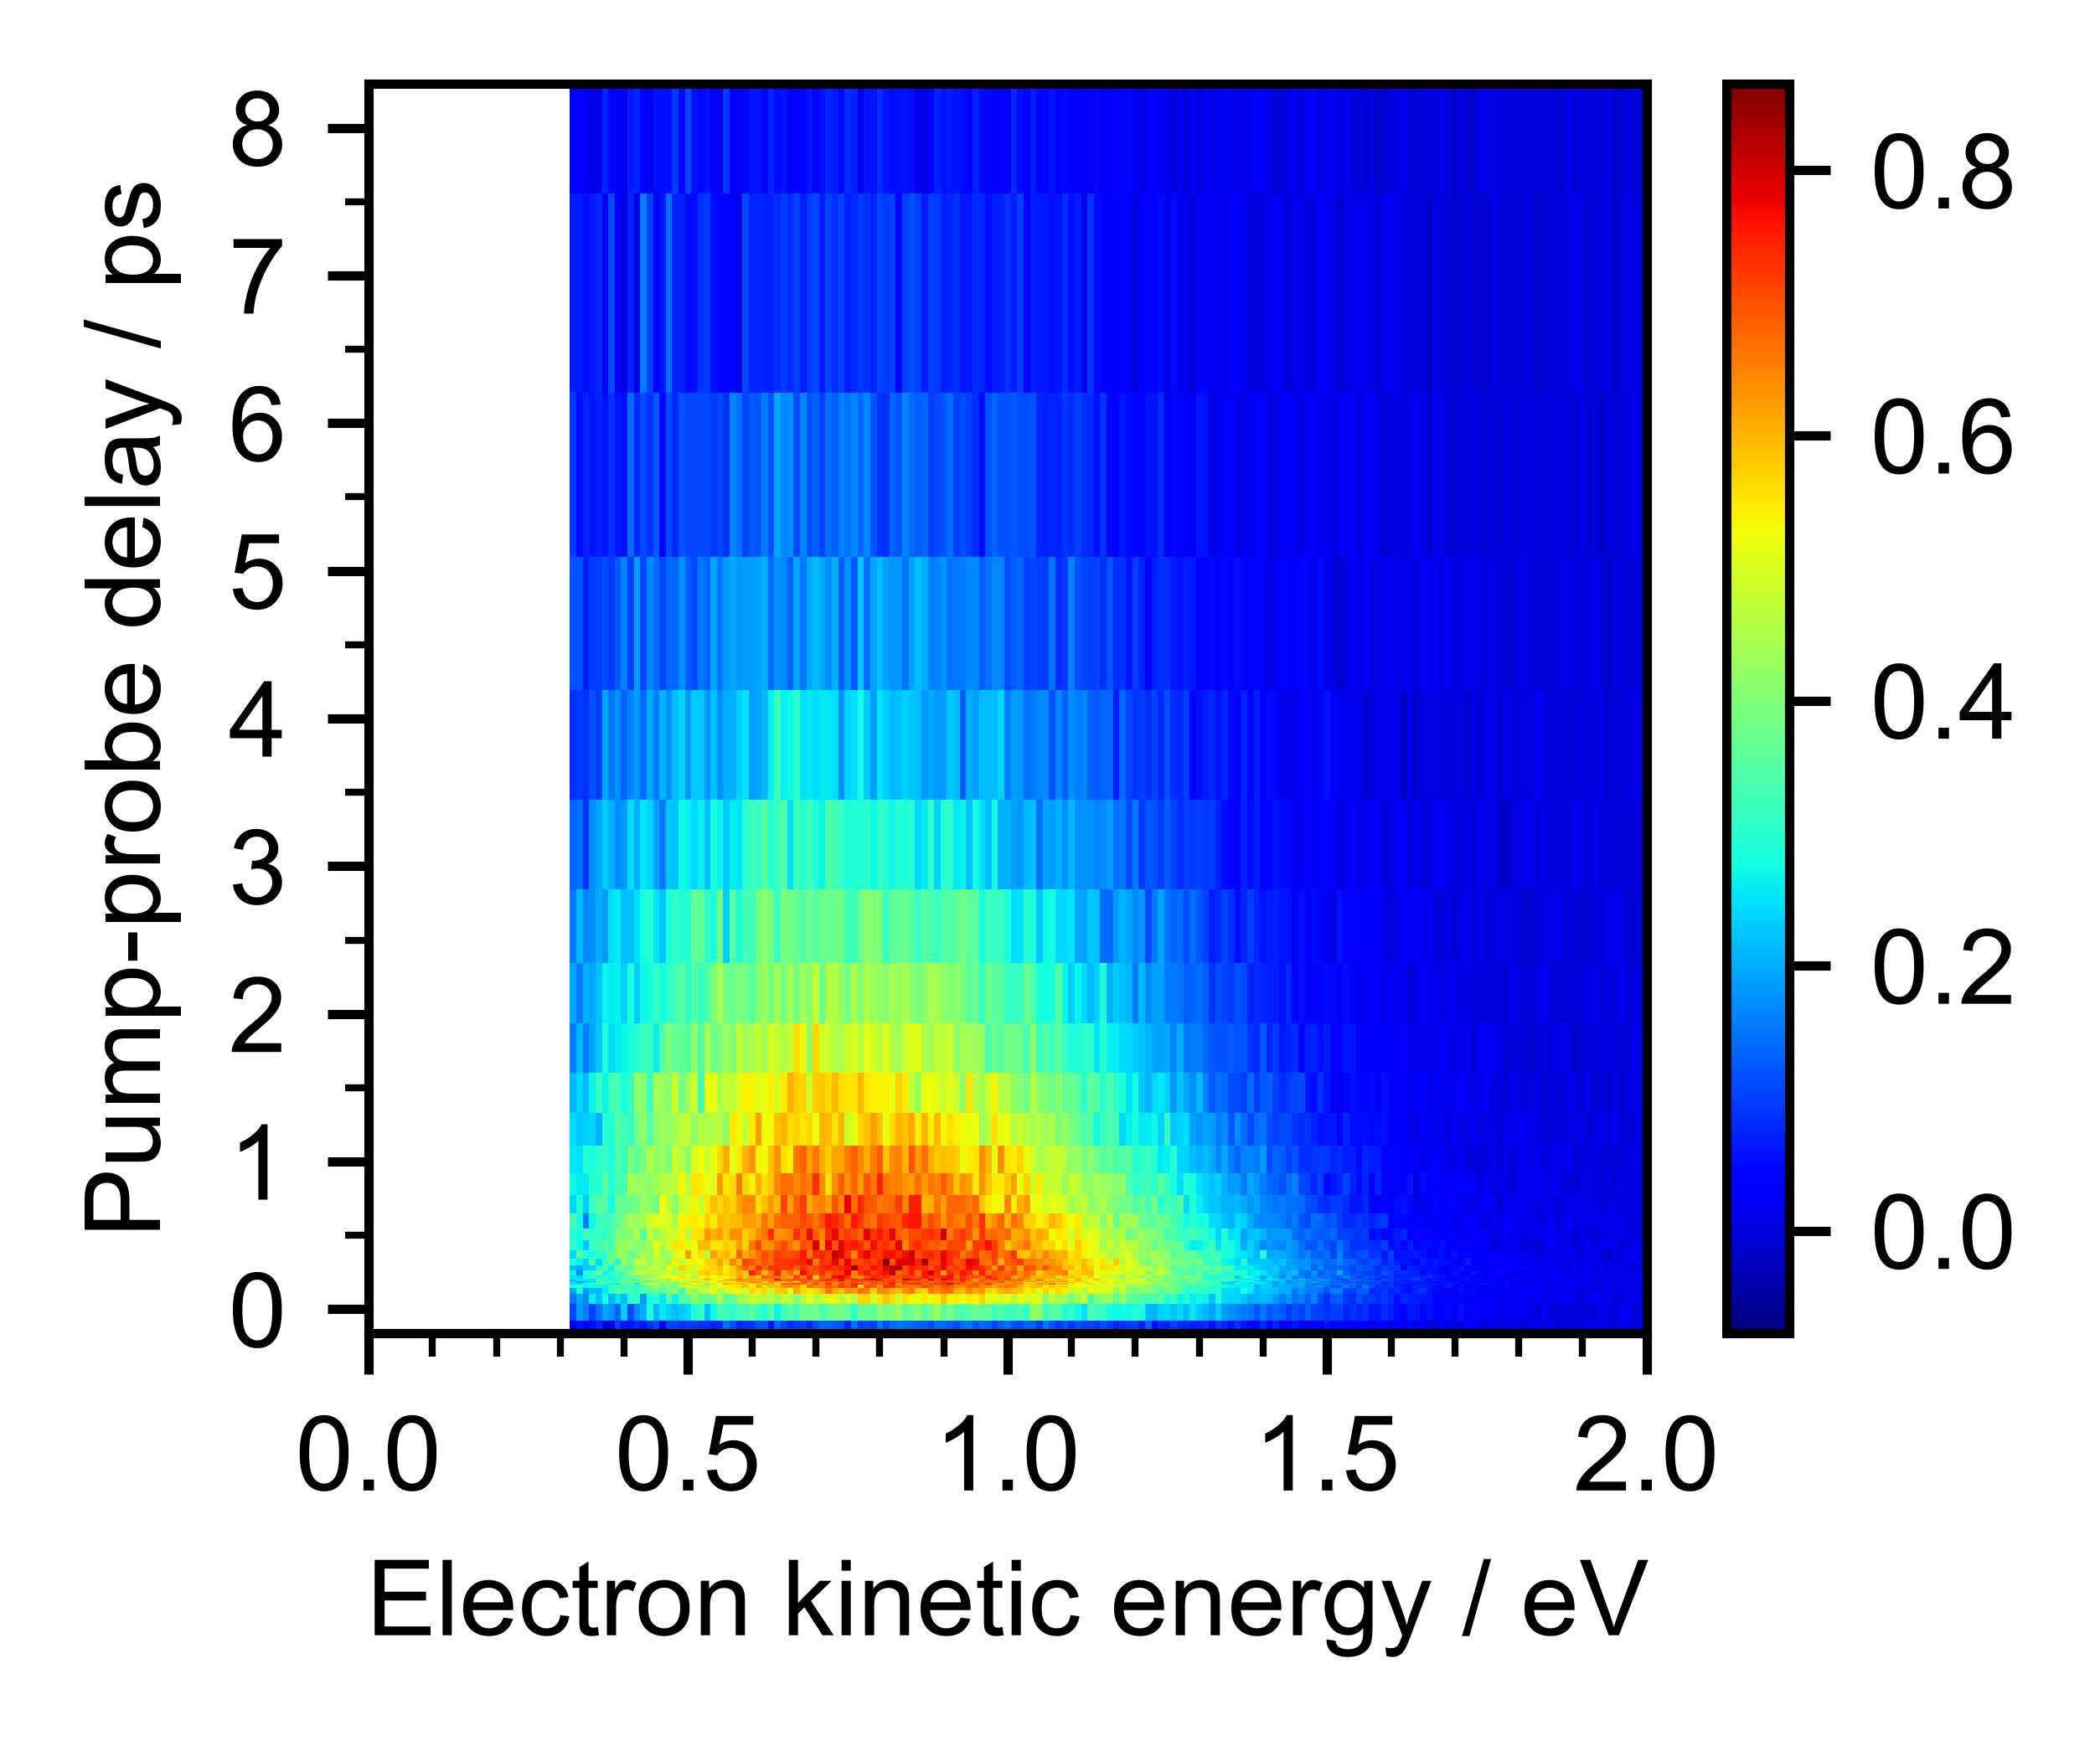

In [34]:
fig,ax = plt.subplots()
fig.set_dpi(1000)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)


im0 = ax.pcolormesh(scanSet.energies_retrieved,
                    scanSet.delays_t0,
                    scanSet.subtracted_grid,
                    cmap='jet',
                    # shading='gouraud',
                    # vmin=-1
                   )


ax.set_xlim(0,2)
ax.set_ylim(-0.16,8.3)
# ax.set_yscale('log')
# ax.set_ylim(0.06,18)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax.yaxis.set_major_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(.5))
plt.colorbar(im0)

#### Residuals heatmap

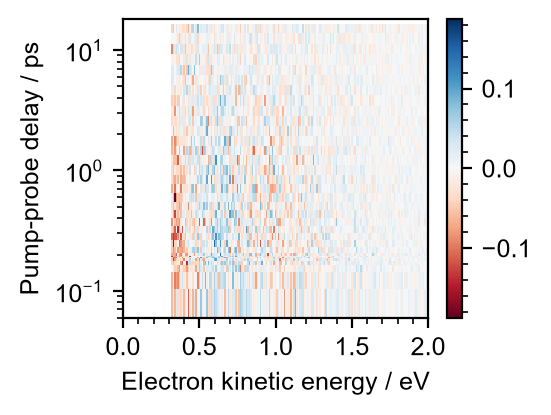

In [35]:
# Data - fit
fig,ax = plt.subplots()
fig.set_dpi(200)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)

im0 = ax.pcolormesh(scanSet.energies_retrieved,
                    scanSet.delays_retrieved,
                    scanSet.subtracted_grid[5:41]-scanSet.subtracted_fit,
                    cmap='RdBu',
                    #center color normalisation around 0
                    norm=mcolors.CenteredNorm()
                    # shading='gouraud',
                   )


ax.set_xlim(0,2)
ax.set_ylim(-0.16,8.3)
ax.set_yscale('log')
ax.set_ylim(0.06,18)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
# ax.yaxis.set_major_locator(MultipleLocator(1))
# ax.yaxis.set_minor_locator(MultipleLocator(.2))
cbar = plt.colorbar(im0)
cbar.ax.yaxis.set_major_locator(MultipleLocator(.1))
cbar.ax.yaxis.set_minor_locator(MultipleLocator(.02))


### Save data

In [36]:
# Save data
savepath = r"data/out/"
# Save retrieved full
save_arr = tr.create_save_arr(scanSet.energies_retrieved_full,
                              scanSet.delays_retrieved,
                              scanSet.subtracted_retrieved_full)

np.savetxt(savepath+"RetrievedData.csv",save_arr, delimiter = ',',fmt = "%.10e")

# Save rebinned onto grid
save_arr = tr.create_save_arr(scanSet.energies_retrieved,
                              scanSet.delays_t0,
                              scanSet.subtracted_grid)

np.savetxt(savepath+"LJscatterGridData.csv",save_arr, delimiter = ',',fmt = "%.10e")


### Total area decay fit

t0, A1, tau1 (Total retrieved area)
[1.1129, 3.3154, 0.0161]
[0.0078, 0.0728, 0.0042]
A1, tau1, t0 (Total counts)
[1.1131, 2.8306, 0.0]
[0.0058, 0.046, 0.0032]


array([1.11307104e+00, 2.83059792e+00, 3.25677312e-06])

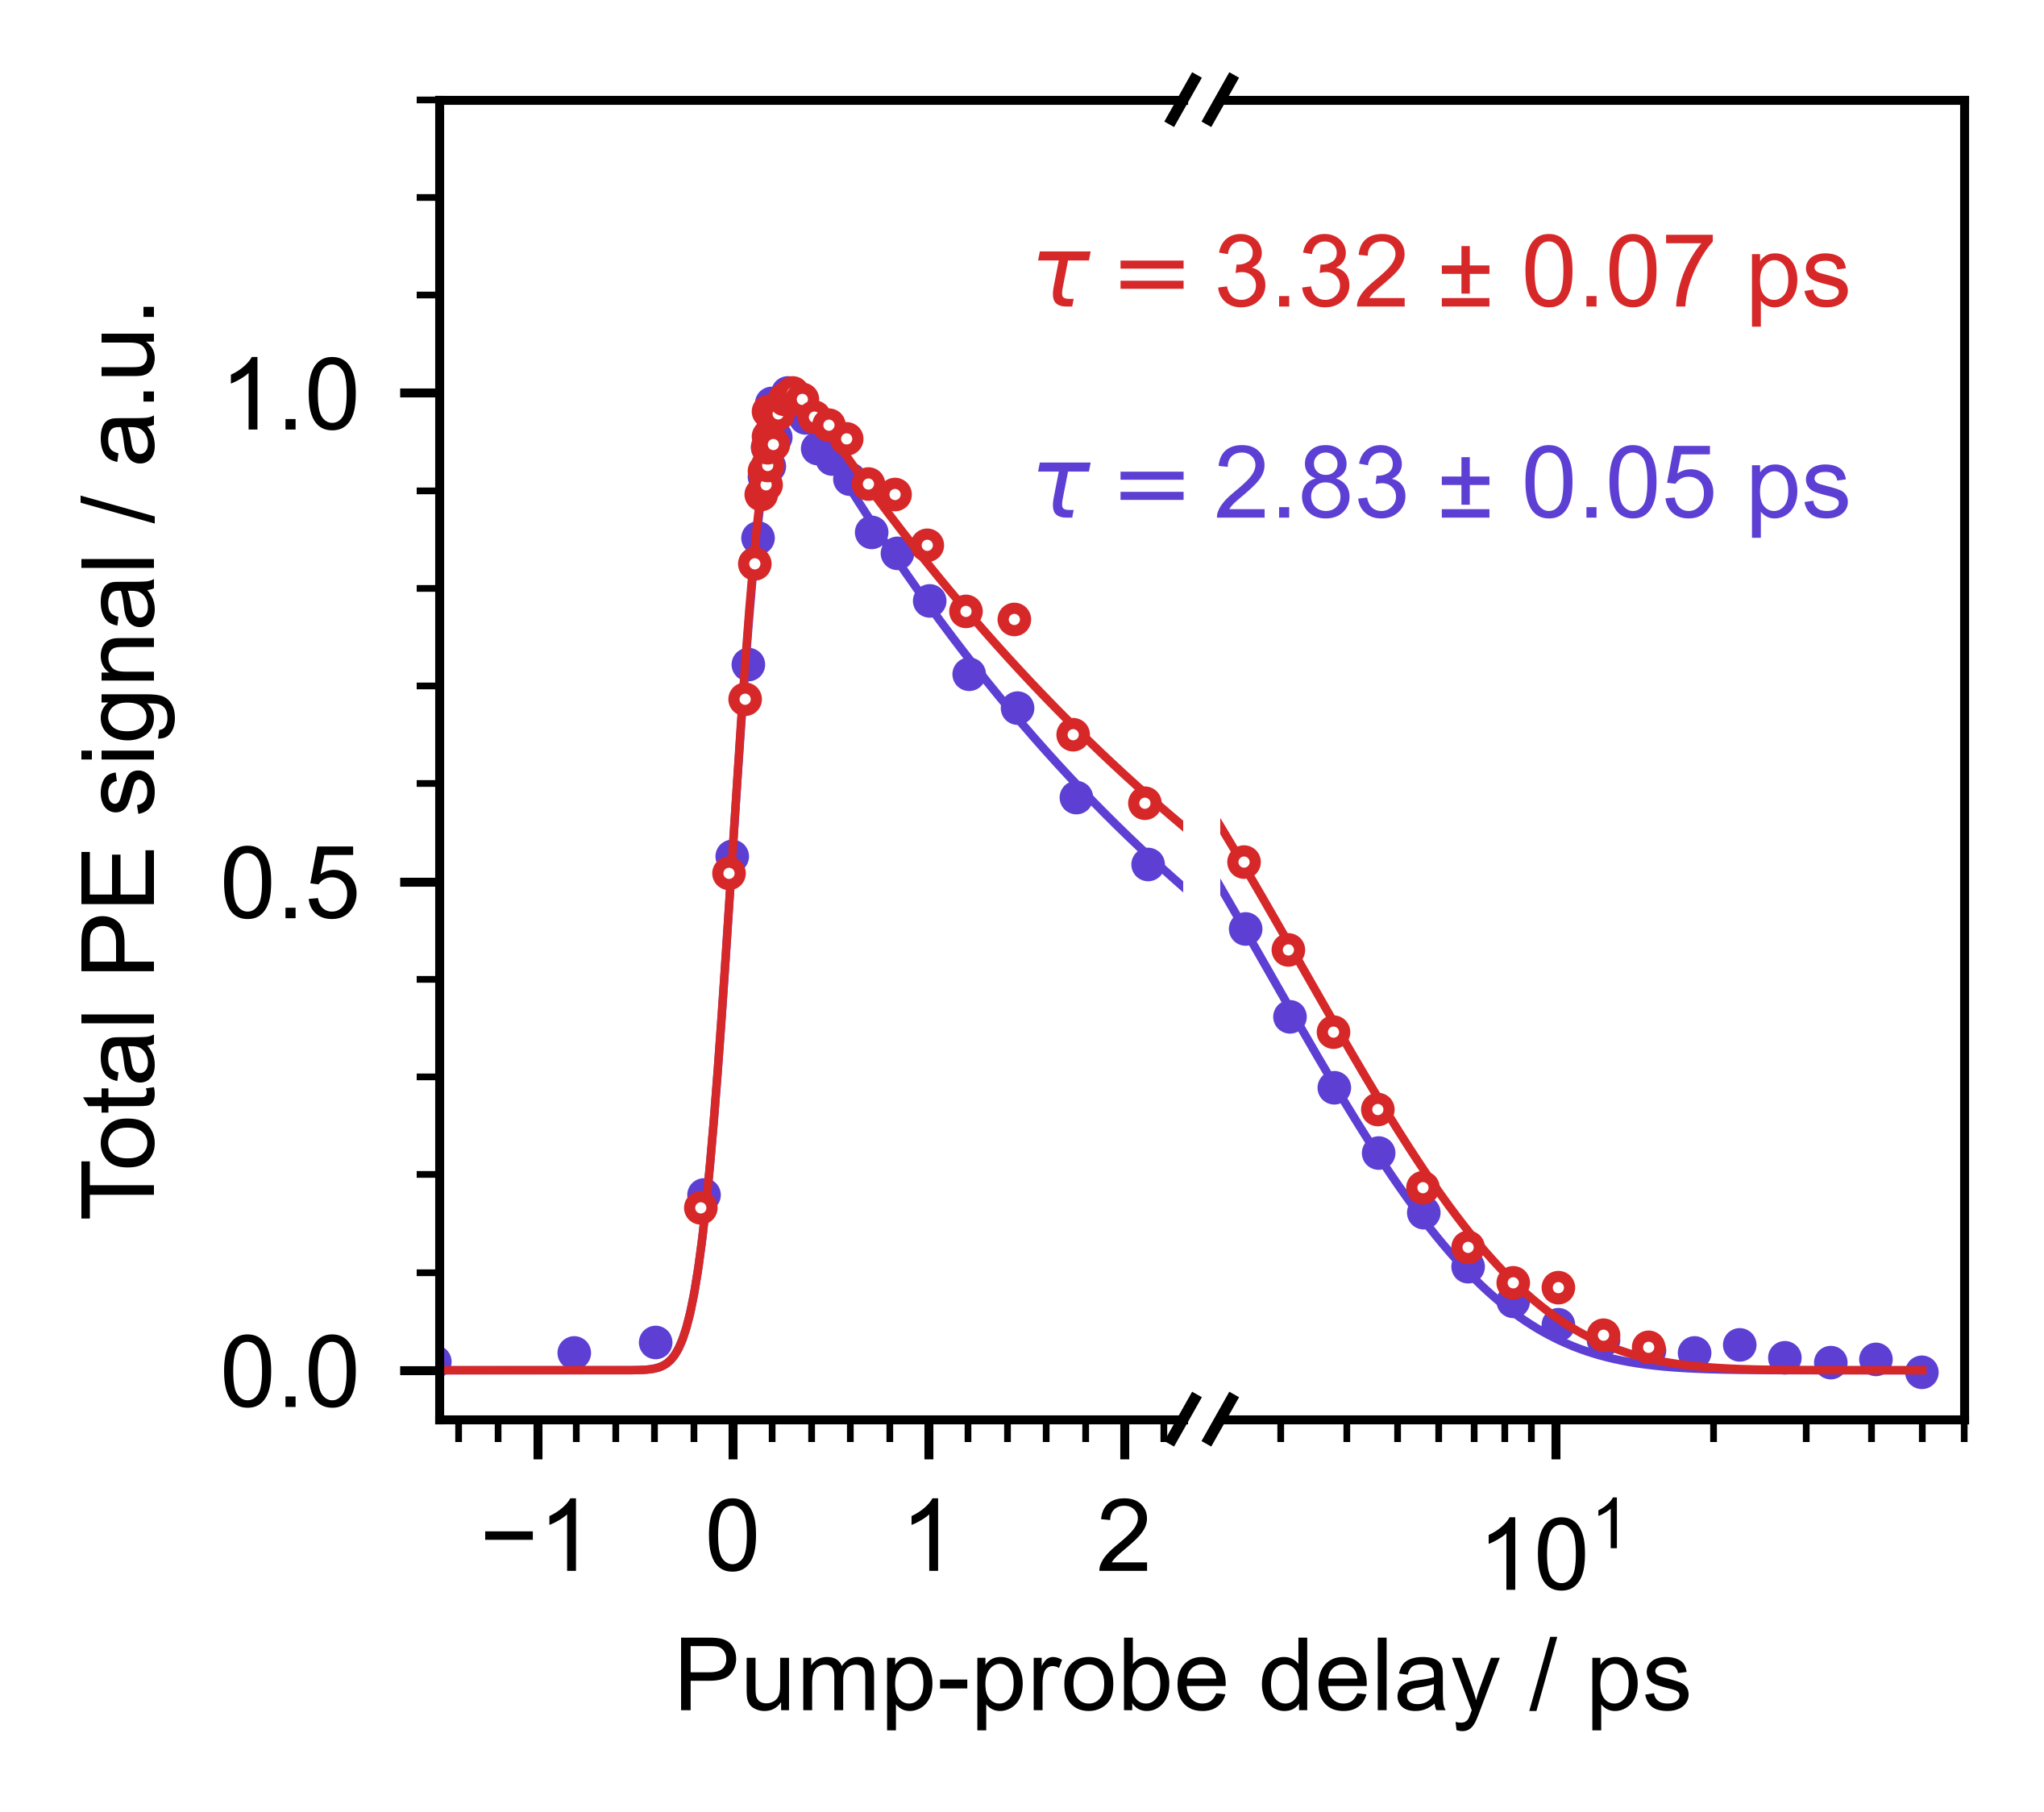

In [37]:
# Fit total retrieved area decay and compare to total counts
fig,axes = plt.subplots(1,2)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(1000)
fig.set_size_inches(15.5/2.5/2.54,13.5/2.54/2.5)
ax0,ax1 = axes
ts  =np.arange(-5,50,0.020)


delays = scanSet.delays_retrieved
trace = scanSet.params_retrieved[:,0]*scanSet.params_retrieved[:,2]
trace/=max(trace)

#Make fit function with pre set SIGMA (you can also let it float if needed)
fit_func = lambda x,A1,tau1,t0: tr.monoexponential_witht0(x,A1,tau1,t0,SIGMA)

params,pcov=curve_fit(fit_func, delays, trace,
                  p0=[1,3,0])
perr = np.sqrt(np.diag(pcov))

# t0 from retrieved
t0 = params[-1]

for ax in axes:
    ax.plot(delays-t0,trace,'o',c=red,markerfacecolor='w',ms=2,zorder=100)
    ax.plot(ts-t0,fit_func(ts,*params),red,lw=.75)
    
    
print("t0, A1, tau1 (Total retrieved area)")
print([float(f"{p:.4f}") for p in params])
print([float(f"{p:.4f}") for p in perr])
    
ax1.text(.85,.76,f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',c=red,transform=ax.transAxes)

#### Total counts
delays = scanSet.delays_t0
#Must integrate
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)

params,pcov=curve_fit(fit_func,delays,trace,
                  p0=[1,3,0])
perr = np.sqrt(np.diag(pcov))

t0 = params[-1]

for ax in axes:
    ax.plot(delays-t0,trace,'o',c=violet,ms=2,zorder=0)
    ax.plot(ts-t0,fit_func(ts,*params),c=violet,lw=.75,zorder=0)
       
print("A1, tau1, t0 (Total counts)")
print([float(f"{p:.4f}") for p in params])
print([float(f"{p:.4f}") for p in perr])
ax1.text(.85,.6,f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",c=violet,ha='right',transform=ax.transAxes)

### 
    
#Formatting
for ax in axes:
    ax.set_ylim(-.05,1.3)

ax0.set_xlim(-1.5,2.299)

ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)

ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)

   
    
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(.1))
ax0.xaxis.set_major_locator(MultipleLocator(1))
ax0.xaxis.set_minor_locator(MultipleLocator(.2))

ax1.xaxis.set_minor_formatter(NullFormatter())

# ax1.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto'))
# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal

    
fig.patch.set_alpha(0)
params

### eKE shift fit

In [38]:
def monoexponential_energy(x,A1,tau1,y0):
    return A1 * np.exp(-x/tau1) + y0

In [39]:
def average_eKE(x, y):
    """Get average eKE by weighing the x values by the area of the trapezoid"""

    #get the difference of the energies
    dx = np.diff(x, axis=-1)
    # get trapezoid areas (b1+b2)*h/2
    area = (y[:, 1:] + y[:, :-1]) * dx / 2

    # Weighted sum of energies
    weighted_sum = np.sum(x[:, :-1] * area, axis=-1)
    total_area = np.sum(area, axis=-1)
    #Return average
    return weighted_sum / total_area    


[0.16452661 1.11692934 0.80673005]
[0.11674636 0.73094204 0.81854146]


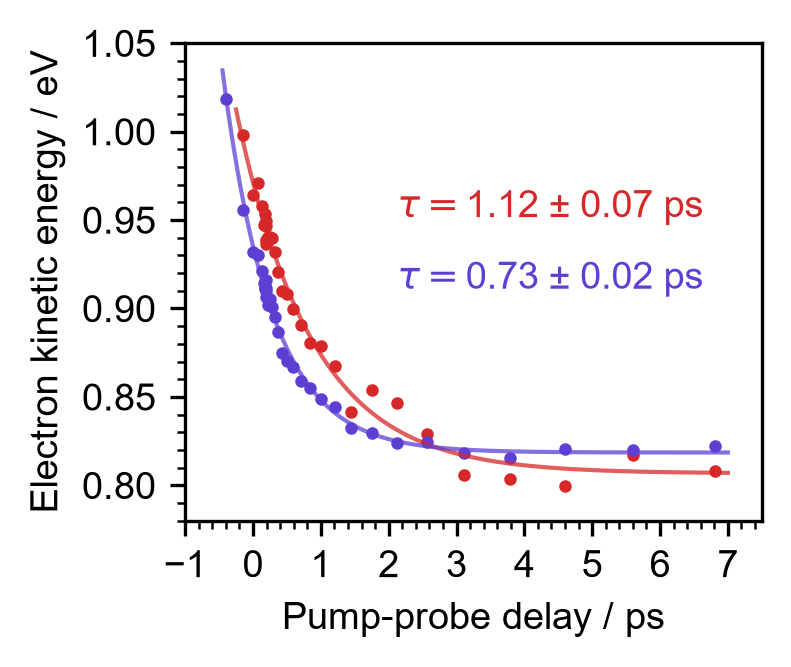

In [40]:
fig,ax = plt.subplots(1)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)


#Plot mean retrieved eKE
ax.plot(scanSet.delays_retrieved,scanSet.params_retrieved[:,1],'o',c=red,ms=2,label='Retrieved')

#Find weighted average (mean eKE)
delays = scanSet.delays_t0
#Stack energies
tiled_energies = np.tile(scanSet.energies,(len(delays),1))
# Get weighted average
weighted_average = average_eKE(tiled_energies,scanSet.subtracted)

# Plot mean eKE (withour data below 0.6ps which has 0 intensity)
ax.plot(delays[delays>-.6],weighted_average[delays>-.6],'o',c=violet,ms=2,label='Mean eKE')


##### Fit retrieved with monoexponential
ds=np.linspace(-0.25,7,501) 
mask = scanSet.delays_retrieved<8
#Fit
params,pcov=curve_fit(monoexponential_energy,
                      scanSet.delays_retrieved[mask],scanSet.params_retrieved[:,1][mask],
                        p0=[1,3,.7])
perr = np.sqrt(np.diag(pcov))
print(params)
ax.plot(ds,monoexponential_energy(ds,*params),c=red,alpha=.75)
ax.text(.9,.55, f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',c=red,transform=ax.transAxes)

##### Fit mean eKE with monoexponential
ds=np.linspace(-0.45,7,501) 

mask = np.logical_and(delays>-.5,delays<8)

#Fit
params,pcov=curve_fit(monoexponential_energy,
                      delays[mask],weighted_average[mask],
                        p0=[1,3,.7])
perr = np.sqrt(np.diag(pcov))
print(params)
ax.plot(ds,monoexponential_energy(ds,*params),c=violet,alpha=.75)
ax.text(.9,.4, f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',c=violet,transform=ax.transAxes)

ax.yaxis.set_major_locator(MultipleLocator(.05))
ax.yaxis.set_minor_locator(MultipleLocator(.01))
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.xaxis.set_minor_locator(MultipleLocator(.2))
ax.set_xlim(-1,7.5)
ax.set_ylim(0.78 ,1.05)
ax.set_xlabel("Pump-probe delay / ps")
ax.set_ylabel("Electron kinetic energy / eV")

fig.patch.set_alpha(0)